# Notebook to generate figures in King et al., 2026 (bioRxiv)

## Overview and data dependencies
This notebook contains code needed to reproduce the figures presented in King et al., 2026 (bioRxiv) [https://doi.org/10.64898/2026.10.16.759478]. The data needed for the code to run properly will be made available on Zenodo [https://doi.org/10.5281/zenodo.23929396]. Because full simulation outputs are prohibitively large to share, they will only be made available upon request. The available data consists of summary simulation ouputs, initial condition files, and four pre-computed datasets, as described in the Zenodo documentation. The data also contains cell data extracted from multiplexed imaging which is used to define initial conditions; that step is not done here.

The notebook is subdivided based on major figures in the paper. Because certain figures have dependencies on data generated in previous figures, this notebook should be run fully and in order (more details about data dependency is available in the Zenodo documentation). In general, we indicate before a certain cell which figure and subpanel its output corresponds to. Although the full simulation data is unavailable, the code used to generate the pre-computed dataset is included either commented out or in "raw" cells (e.g., Jupyter will not run them).

## Software dependencies
To run this notebook, various custom functions must be imported from the `analyzeABM` folder available at this project's GitHub (full path: `python/src/analyzeABM`). If you have copied the structure of the GitHub, meaning that this Python notebook is located within the `python` folder, then you can access this folder by appending the `src` folder path as done in the first cell below (i.e., change `/project2/sfinley_500/tking/abm_testing/` to wherever you have cloned the GitHub repository on your machine (if you have changed the repo name from `breast_cancer` to something else, change that as well). A list of the Python packages required for these functions (and this notebook) to run properly are available in the `pyproject.toml` file within the `python` folder mentioned above.

## Other notes
In the first cell below, please set the maximum number of accessible CPUs on the machine you are using. Certain analyses can be accelerated by multithreading, though this is more important when calculating the pre-computed datasets, so a large number of CPUs is not necessary for running more downstream analyses. Additionally, set paths to the data obtained from the Zenodo repository above.

In general, each zip file should be turned into its own folder (e.g., the contents of `precomputed.zip` will be `precomputed/file_1.ex`, etc.); if you have cloned the GitHub repo, your directory structure should look like:

```
breast_cancer (parent directory)
├── cell_classification/
├── inc/
├── matlab/
├── mihc/ (from mihc.zip)
├── precomputed/ (from precomputed.zip)
├── python
├── simulations/ (from simulations.zip)
│   ├── main_simulations/
│   ├── mdsc_depletion/
│   ├── treg_depletion/
│   ├── sensitivity_analysis_notx/
│   └── sensitivity_analysis_tx/
└── src
```

Finally, certain analyses requires significant amounts of memory for calculation. In tests, running the notebook sequentially requires at least 35 GiB of memory, though this can likely be reduced by manually deleting objects following each analysis step. A cursory evaluation of the size of various objects indicates that the majority of this memory usage derives from the neighborhood analyses done to generate Figure 6, as the number of cells used to calculate neighborhoods is very large.

In [9]:
import tacco
import anndata
import importlib.metadata

In [10]:
print(importlib.metadata.version("tacco"))

0.5.0


In [3]:
# Do all imports here, once
import sys
import os
import matplotlib
import matplotlib.gridspec as gridspec
import multiprocessing
import pickle
import scipy.stats as stats

from umap import UMAP
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import train_test_split
from sklearn.cluster import MiniBatchKMeans
from scipy.cluster.hierarchy import dendrogram
from scipy.stats import ttest_ind
from scipy.stats import mannwhitneyu
from cycler import cycler
from statannotations.Annotator import Annotator
from matplotlib.colors import ListedColormap

# Import custom functions
sys.path.append('/project2/sfinley_500/tking/abm_testing/breast_cancer/python/src')
from analyzeABM import *

# Set paths to imported data (either use base + remainder or fully specify each path)
base = "/project2/sfinley_500/tking/abm_testing/breast_cancer"
path_to_simulations = f"{base}/simulations/simulations_may2026"                 # ('main_simulations' in 'simulations.zip')
path_to_mdsc_dep = f"{base}/simulations/simulations_aug2026/mdsc_gen_depletion" # ('mdsc_depletion' in 'simulations.zip')
path_to_treg_dep = f"{base}/simulations/simulations_aug2026/treg_gen_depletion" # ('treg_depletion' in 'simulations.zip')
path_to_notx_sa = f"{base}/simulations/sa_may2026_notx"                         # ('sensitivity_analysis_notx' in 'simulations.zip')
path_to_tx_sa = f"{base}/simulations/sa_jul2026_tx"                             # ('sensitivity_analysis_tx' in 'simulations.zip')
path_to_mihc = f"{base}/mihc"                                                   # (from 'mihc.zip')
path_to_precomputed = f"{base}/precomputed"                                     # (from 'precomputed.zip')

# Set fontsizes for all graphs
plt.rcParams.update({
    'axes.titlesize': 10,
    'axes.labelsize': 8,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'legend.title_fontsize':8
})

# The runtime of various analyses can be improved by multithreading, so set the number of accessible CPUs here
cpu_count = 64

OMP: Info #277: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


## Figure 1 -- Methods

These cells generate images used to explain our methods. These do not show results and are purely illustrative.

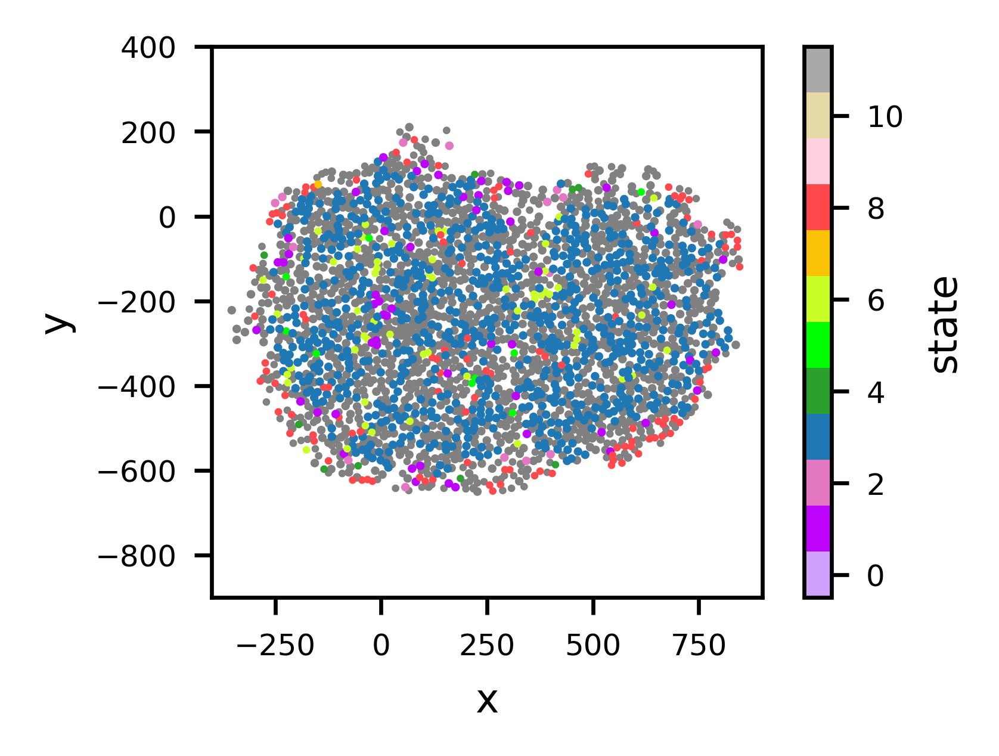

In [2]:
df = pd.read_csv(f"{path_to_mihc}/in_silico_117.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1300 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

df_generalized = df[df.state.isin([9, 10, 11])]
df_nongeneralized = df[~df.state.isin([9, 10, 11])]

df_keep = df_nongeneralized.sample(frac=0.5, random_state=0)
df_reject = df_nongeneralized.drop(df_keep.index)
df_reject = pd.concat([df_reject, df_generalized])

fig, ax = plt.subplots(figsize=(3, 2), dpi=600)
df_reject.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = 'gray', xlim=(-400, 900), ylim=(-900, 400))
df_keep.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-400, 900), ylim=(-900, 400))

ax.set()
ax.set_aspect(1)

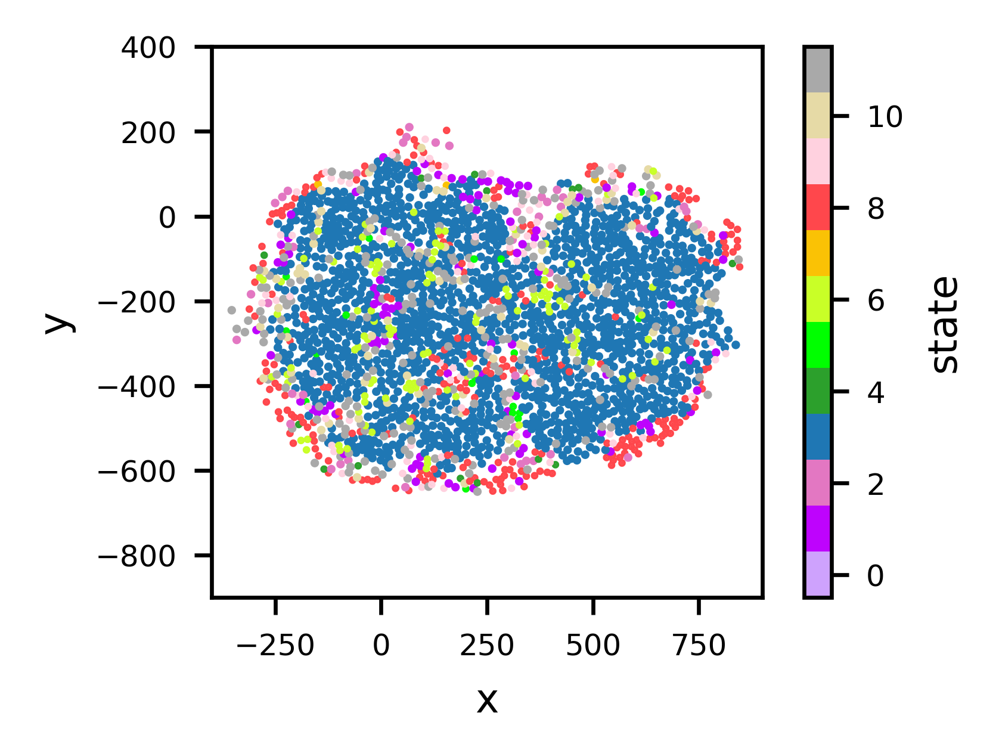

In [3]:
df = pd.read_csv(f"{path_to_mihc}/in_silico_117.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1300 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

fig, ax = plt.subplots(figsize=(3, 2), dpi=600)
df.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-400, 900), ylim=(-900, 400))
ax.set_aspect(1)

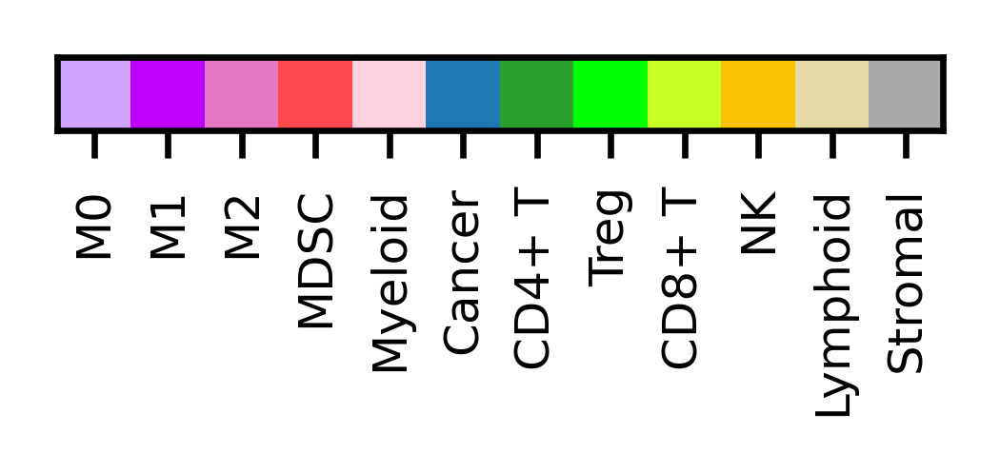

In [4]:
fig, ax = plt.subplots(figsize=(2, 0.5))
fig.set_dpi(600)

reorder = [0, 1, 2, 8, 9, 3, 4, 5, 6, 7, 10, 11]
ax.imshow([[np.arange(len(cell_colors))[i] for i in reorder]], cmap=cell_cmap)
ax.set_xticks(np.arange(len(cell_colors)), [["M0", "M1", "M2", "Cancer", "CD4+ T", "Treg", "CD8+ T", "NK", "MDSC", "Myeloid", "Lymphoid", "Stromal"][i] for i in reorder], rotation=90)
ax.yaxis.set_visible(False)

## Supplementary Figure S2 -- Conducting sensitivity analyses on key exhaustion-related parameters validates their values.

The cell below generates **Sup. Fig. S2B**, which shows sensitivity analyses for selected parameters.

/tmp/SLURM_6780182/ipykernel_3468985/1207326179.py:89: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


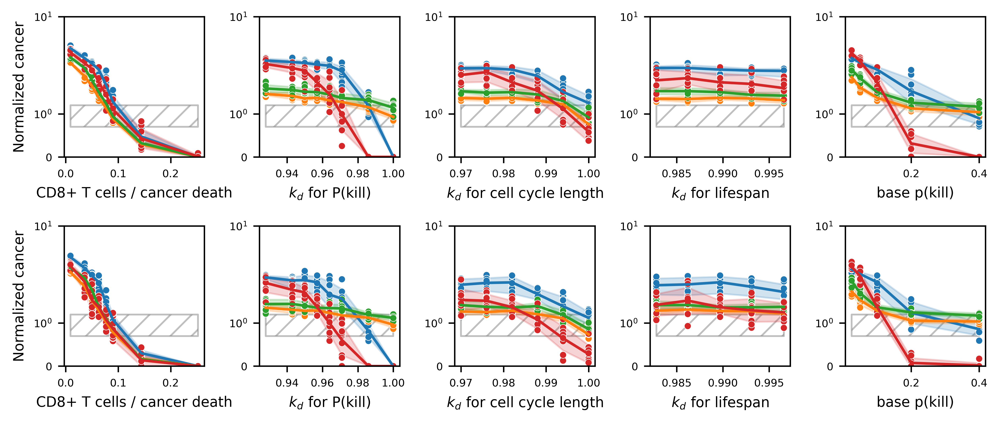

In [5]:
# This plots the sensitivity analysis curves for the selected metastases
fig, ax = plt.subplots(2, 5, figsize = (8, 3.5), dpi=600, constrained_layout="True")

# These are the values
cd8recs = [0.009, 0.036, 0.050, 0.063, 0.077, 0.090, 0.144, 0.252]
cd8kdkp = [0.928, 0.943, 0.950, 0.957, 0.964, 0.971, 0.986, 1.000]
cd8kdprol = [0.970, 0.976, 0.982, 0.988, 0.994, 1.000]
cd8kdeath = [0.9828, 0.9862, 0.9897, 0.9931, 0.9966]
cd8basekill = [0.025, 0.05, 0.1, 0.2, 0.4]

# CD8 recruitment
x_span = max(cd8recs) - min(cd8recs)
xlims = (min(cd8recs) - 0.05*x_span, max(cd8recs) + 0.05*x_span)
plot_tp_sa_curve(path_to_notx_sa, "cd8rec", cd8recs, metric="n_cancer", 
                 ax=ax[0,0], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[0,0].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="CD8+ T cells / cancer death", ylabel="Normalized cancer")
ax[0,0].get_legend().remove()

plot_tp_sa_curve(path_to_tx_sa, "cd8rec", cd8recs, metric="n_cancer", 
                 ax=ax[1,0], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[1,0].get_legend().remove()
ax[1,0].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="CD8+ T cells / cancer death", ylabel="Normalized cancer")

# CD8 kill prob decay
x_span = max(cd8kdkp) - min(cd8kdkp)
xlims = (min(cd8kdkp) - 0.05*x_span, max(cd8kdkp) + 0.05*x_span)
plot_tp_sa_curve(path_to_notx_sa, "cd8kdpkill", cd8kdkp, metric="n_cancer", 
                 ax=ax[0,1], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[0,1].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for P(kill)", ylabel="")
ax[0,1].get_legend().remove()

plot_tp_sa_curve(path_to_tx_sa, "cd8kdpkill", cd8kdkp, metric="n_cancer", 
                 ax=ax[1,1], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[1,1].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for P(kill)", ylabel="")
ax[1,1].get_legend().remove()

# CD8 cell cycle decay
x_span = max(cd8kdprol) - min(cd8kdprol)
xlims = (min(cd8kdprol) - 0.05*x_span, max(cd8kdprol) + 0.05*x_span)
plot_tp_sa_curve(path_to_notx_sa, "cd8kdprol", cd8kdprol, metric="n_cancer",
                 ax=ax[0,2], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[0,2].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for cell cycle length", ylabel="")
ax[0,2].get_legend().remove()

plot_tp_sa_curve(path_to_tx_sa, "cd8kdprol", cd8kdprol, metric="n_cancer",
                 ax=ax[1,2], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[1,2].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for cell cycle length", ylabel="")
ax[1,2].get_legend().remove()

# CD8 death
x_span = max(cd8kdeath) - min(cd8kdeath)
xlims = (min(cd8kdeath) - 0.05*x_span, max(cd8kdeath) + 0.05*x_span)
plot_tp_sa_curve(path_to_notx_sa, "cd8kdeath", cd8kdeath, metric="n_cancer", 
                 ax=ax[0,3], plot_data=True, time=600, reverse_labels=False, numerical_labels=False, num_dec=4)
ax[0,3].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for lifespan", ylabel="")
ax[0,3].get_legend().remove()

plot_tp_sa_curve(path_to_tx_sa, "cd8kdeath", cd8kdeath, metric="n_cancer", 
                 ax=ax[1,3], plot_data=True, time=600, reverse_labels=False, numerical_labels=False, num_dec=4)
ax[1,3].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="$k_d$ for lifespan", ylabel="")
ax[1,3].get_legend().remove()

# CD8 base kill
x_span = max(cd8basekill) - min(cd8basekill)
xlims = (min(cd8basekill) - 0.05*x_span, max(cd8basekill) + 0.05*x_span)
plot_tp_sa_curve(path_to_notx_sa, "cd8basekill", cd8basekill, metric="n_cancer", 
                 ax=ax[0,4], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[0,4].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="base p(kill)", ylabel="")
ax[0,4].get_legend().remove()

plot_tp_sa_curve(path_to_tx_sa, "cd8basekill", cd8basekill, metric="n_cancer", 
                 ax=ax[1,4], plot_data=True, time=600, reverse_labels=False, numerical_labels=False)
ax[1,4].set(yscale="symlog", ylim=(0, 10), xlim=xlims, title="",
           xlabel="base p(kill)", ylabel="")
ax[1,4].get_legend().remove()

for axis in ax.flatten():
    axis.set_box_aspect(1)

fig.tight_layout()

The cell below generates **Sup. Fig. S2A**, which shows the immune composition of mets selected for sensitivity analysis relative to the complete cohort.

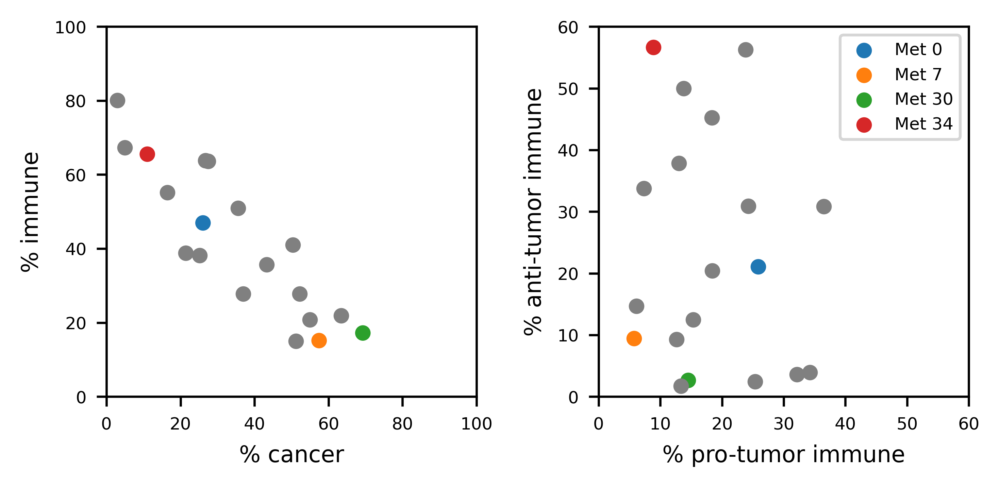

In [6]:
other_mets = [106, 108, 112, 113, 114, 117, 122, 123, 125, 128, 132, 140, 142, 143, 145]
sa_mets = [100, 107, 130, 134]
num_to_type = {0: "M0", 1: "M1", 2: "M2", 3: "cancer", 4: "CD4", 5: "Treg", 6: "CD8", 8: "NK", 10: "MDSC", 11: "myeloid", 12: "lymphoid", 13: "stromal"}
cells = ["M0", "M1", "M2", "cancer", "CD4", "Treg", "CD8", "NK", "MDSC", "myeloid", "lymphoid", "stromal"]

def vcs_to_array(vcs):
    array = np.zeros(12)
    for i, cell in enumerate(cells):
        if cell in vcs.keys():
            array[i] = vcs[cell]
    return array

vcs = []
for met in (other_mets + sa_mets):
    df = pd.read_csv(f"{path_to_mihc}/in_silico_{met}.csv", header=None, names=["uid", "x", "y", "celltype", "area"]) # Read in the data
    vc = df["celltype"].apply(lambda x: num_to_type[x]).value_counts() # Get value counts
    vcs.append(vcs_to_array(vc))

# Format value counts correctly
vcs = np.array(vcs)
vc_df = pd.DataFrame(vcs, columns=cells)
vc_df.index = (other_mets + sa_mets)

# Define new summary columns
vc_df["n_cells"] = vc_df.astype(np.float32).sum(axis=1)
vc_df["% pro tumor"] = 100*vc_df[["M2", "Treg", "MDSC"]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["% anti tumor"] = 100*vc_df[["M1", "CD4", "CD8", "NK"]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["% immune"] = 100*vc_df[["M1", "CD4", "CD8", "NK", "M2", "Treg", "MDSC"]].astype(np.float32).sum(axis=1) / vc_df["n_cells"]
vc_df["% cancer"] = 100*vc_df["cancer"] / vc_df["n_cells"]

# Plot the two comparisons
fig, ax = plt.subplots(1, 2, figsize=(5, 3), dpi=600)

# Do these 1 at a time for the legend
vc_df.loc[[100]].plot.scatter("% pro tumor", "% anti tumor", c=["tab:blue"], label="Met 0", colorbar=False, ax=ax[1])
vc_df.loc[[107]].plot.scatter("% pro tumor", "% anti tumor", c=["tab:orange"], label="Met 7", colorbar=False, ax=ax[1])
vc_df.loc[[130]].plot.scatter("% pro tumor", "% anti tumor", c=["tab:green"], label="Met 30", colorbar=False, ax=ax[1])
vc_df.loc[[134]].plot.scatter("% pro tumor", "% anti tumor", c=["tab:red"], label="Met 34", colorbar=False, ax=ax[1])
ax[1].legend()

vc_df.loc[sa_mets].plot.scatter("% cancer", "% immune", c=["tab:blue", "tab:orange", "tab:green", "tab:red"], colorbar=False, ax=ax[0])
vc_df.loc[other_mets].plot.scatter("% cancer", "% immune", c="grey", colorbar=False, ax=ax[0])
vc_df.loc[other_mets].plot.scatter("% pro tumor", "% anti tumor", c="grey", colorbar=False, ax=ax[1])

ax[0].set(xlim=(0, 100), ylim=(0, 100))
ax[0].set_aspect(1)

ax[1].set(xlim=(0, 60), ylim=(0, 60), xlabel="% pro-tumor immune", ylabel="% anti-tumor immune")
ax[1].set_aspect(1)

fig.tight_layout()

## Figure 2 -- Simulated dynamics of cell counts without treatment. 

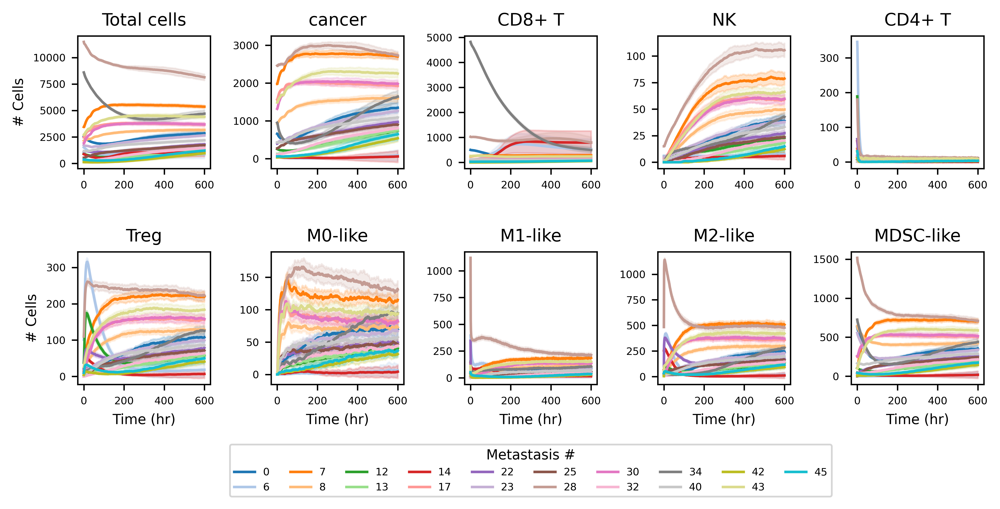

In [7]:
# Get all metastases
mets = [100, 106, 107, 108, 112, 113, 114, 117, 122, 123, 125, 128, 130, 132, 134, 140, 142, 143, 145]

# Set tab20 colormap as the default
colors = plt.get_cmap('tab20').colors
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

# - The first row of each section is [Cancer, CD8+, NK, Th, Treg]
# - The second row of each section is [M0, M1, M2, MDSC, LEGEND]
fig, ax = plt.subplots(2, 5, figsize=(8, 3.8), dpi=600)
ctype_to_axis = {"c":ax[0,1],   "cd8":ax[0,2], "nk":ax[0,3], "cd4_th":ax[0,4], "cd4_treg":ax[1,0],
                 "m0":ax[1,1] , "m1":ax[1,2],  "m2":ax[1,3], "mdsc":ax[1,4]}
ctype_to_fullname = {"c":"cancer",   "cd8":"CD8+ T", "nk":"NK", "cd4_th":"CD4+ T", "cd4_treg":"Treg", 
                     "m0":"M0-like" , "m1":"M1-like",  "m2":"M2-like", "mdsc":"MDSC-like"}

# Iterate over mets and plot
tc_dfs = []
for i, met in enumerate(mets):
    path_notx = os.path.join(path_to_simulations, f"mIHC_{met}") # Obtain path
    met_notx = retrieve_ts(path_notx, num_replicates=25) # Data read-in

    tot_count = []
    for j in range(25):
        tot_cells = met_notx['c'][f"{j}"]
        for ctype in list(ctype_to_axis.keys())[1:]:
            tot_cells = tot_cells + met_notx[ctype][f"{j}"]
        tot_cells = tot_cells + met_notx["myeloid"][f"{j}"] + met_notx["lymphoid"][f"{j}"] + met_notx["stromal"][f"{j}"]
        tot_count.append(tot_cells)
    tot_count = pd.DataFrame(tot_count)
    
    for ctype in ctype_to_axis.keys():
        plot_ts(met_notx, types_to_plot=[ctype], ax=ctype_to_axis[ctype]) # Plot data

    melt = tot_count.melt(var_name='Time', value_name="Total cells", ignore_index=False)
    tc_dfs.append(melt)
    melt["Replicate"] = melt.index
    melt.head()
    sns.lineplot(data=melt, x="Time", y="Total cells", errorbar=("sd", 1), ax=ax[0,0])
    ax[0,0].set(xlabel="", ylabel="", title="Total cells")
    ax[0,0].set_box_aspect(1)
        
# Adjust labels
for ctype in ctype_to_axis.keys():
    ctype_to_axis[ctype].set(ylabel="", title=ctype_to_fullname[ctype])
    ctype_to_axis[ctype].set_box_aspect(1) # Make everything square
    if ctype not in ["cd4_treg", "m0", "m1", "m2", "mdsc"]:
            ctype_to_axis[ctype].set(xlabel="")

# Tight layout to prevent bad overlaps
fig.tight_layout()

# Apply figure legend
artists = []
for item in ax[1,2].get_children():
    if type(item) == matplotlib.lines.Line2D:
        artists.append(item)
ax[1,2].legend(artists, [met - 100 for met in mets], loc='center', ncol=10, title="Metastasis #", bbox_to_anchor=(0.5, -0.65)) # Put the legend under the bottom middle axis

ax[0,0].set(ylabel="# Cells")
ax[1,0].set(ylabel="# Cells")

# Get / save axis x-lims if you need to generate other plots (e.g., for presentation)
ylims = []
for axis in ax.flatten():
    ylims.append(axis.get_ylim())

## Figure 3 -- Classification of metastases based on endpoint cancer growth & identification of metastases with statistically significant treatment (anti-PD-1 + anti-CTLA-4) effect.

In [8]:
# Look at every met, extract the final states (LAST DAY), plot irRECIST
mets = [0, 6, 7, 8, 12, 13, 14, 17, 22, 23, 25, 28, 30, 32, 34, 40, 42, 43, 45]
num_replicates = 25

all_results = []
for met in mets:
    for j in range(num_replicates):
        path = os.path.join(path_to_simulations, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        tx_path = os.path.join(path_to_simulations, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        data = pd.read_csv(path, header=0)
        tx_data = pd.read_csv(tx_path, header=0)
        all_results.append([data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "no tx"])
        all_results.append([tx_data["c"].tolist()[-1], tx_data["c"].tolist()[0], f"Met {met}", "tx"])

all_results = pd.DataFrame(all_results, columns=["Final cancer", "Initial cancer", "Met", "Treatment"])
all_results["Normalized no. cancer"] = all_results["Final cancer"].astype(float) / all_results["Initial cancer"].astype(float)
all_results["Normalized sqrt(no. cancer)"] = np.sqrt(all_results["Final cancer"].astype(float)) / np.sqrt(all_results["Initial cancer"].astype(float))

# These are known to not have bimodal distributions
mets = [0, 7, 8, 12, 13, 17, 22, 23, 25, 28, 30, 32, 34, 40, 42, 43, 45]
stat_results = []
for met in mets:
    met_results = all_results[all_results["Met"] == f"Met {met}"]
    notx_vals = met_results[met_results["Treatment"] == "no tx"]
    notx_vals = notx_vals["Normalized no. cancer"]
    tx_vals = met_results[met_results["Treatment"] == "tx"]
    tx_vals = tx_vals["Normalized no. cancer"]
    result = ttest_ind(notx_vals, tx_vals)
    stat_results.append(result)

sr_df = pd.DataFrame(stat_results)
sr_df["Met"] = mets
sr_df["Test"] = "ttest"

# These are known to have bimodal distributions
mets = [6, 14]
stat_results = []
for met in mets:
    met_results = all_results[all_results["Met"] == f"Met {met}"]
    notx_vals = met_results[met_results["Treatment"] == "no tx"]
    notx_vals = notx_vals["Normalized no. cancer"]
    tx_vals = met_results[met_results["Treatment"] == "tx"]
    tx_vals = tx_vals["Normalized no. cancer"]
    result = mannwhitneyu(notx_vals, tx_vals)
    stat_results.append(result)
    
mwu_df = pd.DataFrame(stat_results)
mwu_df["Met"] = mets
mwu_df["Test"] = "mannwhitneyu"

stats_df = pd.concat([sr_df, mwu_df])
stats_df.set_index('Met', inplace=True)
stats_df.sort_index(inplace=True)

# Set significance boolean
alpha = 0.05
stats_df["Significant"] = (stats_df["pvalue"] < alpha)

# Get info about population means
notx_means = []
tx_means = []
for met in stats_df.index:
    notx = all_results[(all_results["Met"] == f'Met {met}') * (all_results["Treatment"] == 'no tx')]
    tx = all_results[(all_results["Met"] == f'Met {met}') * (all_results["Treatment"] == 'tx')]
    notx_means.append(notx["Normalized no. cancer"].mean())
    tx_means.append(tx["Normalized no. cancer"].mean())
    
stats_df["notx mean"] = notx_means
stats_df["tx mean"] = tx_means
stats_df["tx effect (raw)"] = stats_df["notx mean"] - stats_df["tx mean"]
stats_df["tx effect (%)"] = 100 * stats_df["tx effect (raw)"] / stats_df["notx mean"]

# Show significant results
stats_df.sort_values('Significant', ascending=False)

,statistic,pvalue,Test,Significant,notx mean,tx mean,tx effect (raw),tx effect (%)
Met,,,,,,,,
7,4.351248,0.000070,ttest,True,1.367854,1.299777,0.068077,4.976914
8,2.047850,0.046067,ttest,True,1.720560,1.657524,0.063036,3.663664
43,3.264278,0.002027,ttest,True,1.516577,1.438760,0.077817,5.131076
40,2.305836,0.025484,ttest,True,2.551756,2.435691,0.116066,4.548458
17,2.232421,0.030288,ttest,True,1.237069,1.190900,0.046170,3.732181
34,2.860180,0.006251,ttest,True,1.728303,1.548325,0.179979,10.413618
30,4.523352,0.000040,ttest,True,1.503417,1.413090,0.090326,6.008081
0,0.614042,0.542087,ttest,False,2.049498,2.018447,0.031050,1.515016
28,1.417643,0.162754,ttest,False,1.110358,1.091008,0.019350,1.742645


The below cell generates **Figure 3**.

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Met 7_no tx vs. Met 7_tx: t-test independent samples, P_val:7.044e-05 t=4.351e+00
Met 8_no tx vs. Met 8_tx: t-test independent samples, P_val:4.607e-02 t=2.048e+00
Met 17_no tx vs. Met 17_tx: t-test independent samples, P_val:3.029e-02 t=2.232e+00
Met 30_no tx vs. Met 30_tx: t-test independent samples, P_val:4.000e-05 t=4.523e+00
Met 34_no tx vs. Met 34_tx: t-test independent samples, P_val:6.251e-03 t=2.860e+00
Met 43_no tx vs. Met 43_tx: t-test independent samples, P_val:2.027e-03 t=3.264e+00
Met 40_no tx vs. Met 40_tx: t-test independent samples, P_val:2.548e-02 t=2.306e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04



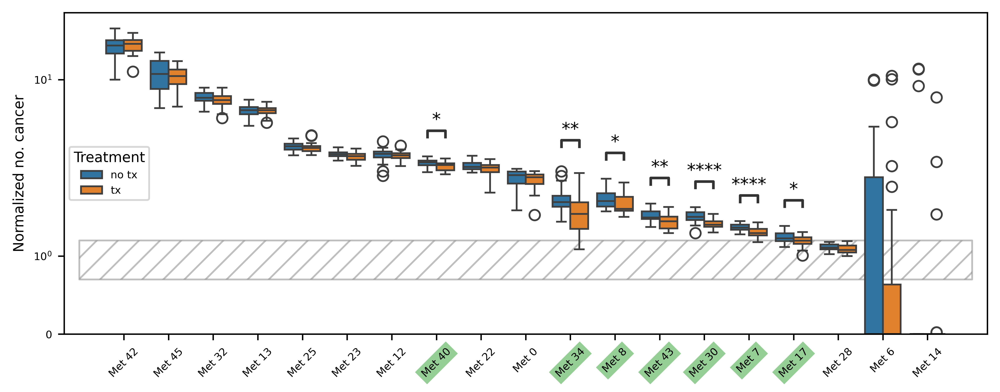

In [9]:
# Set tab20 colormap as the default
colors = plt.get_cmap('tab10').colors
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

all_results['Met'] = all_results['Met'].astype('category')
all_results['Met'] = all_results['Met'].cat.reorder_categories(
    ['Met 42', 'Met 45', 'Met 32', 'Met 13', 'Met 25', 'Met 23', 'Met 12', 'Met 40', 'Met 22', 'Met 0', 'Met 34', 
     'Met 8', 'Met 43', 'Met 30', 'Met 7', 'Met 17', 'Met 28', 'Met 6', 'Met 14'])

ttest_comp = [((met, "no tx"), (met, "tx")) for met in all_results.Met.unique()[(all_results.Met.unique() != "Met 6") & (all_results.Met.unique() != "Met 14")]]
mannwhitney_comp = [(("Met 6", "no tx"),("Met 6", "tx")), 
                    (("Met 14", "no tx"),("Met 14", "tx"))]

fig, ax = plt.subplots(1, 1, figsize=(8, 3.2), dpi=600)
ax.fill_between(np.arange(-1, 20), 0.7, 1.2, color='grey', alpha=0.5, hatch="//", facecolor='none')
sns.boxplot(data=all_results, x="Met", y="Normalized no. cancer", hue="Treatment", ax=ax)
ax.set(yscale='symlog', ylim=(0, 30), title="", xlabel="")
ax.tick_params(axis='x', rotation=45)

annotator1 = Annotator(ax=ax, data=all_results, pairs=ttest_comp, x="Met", y="Normalized no. cancer", hue="Treatment")
annotator1.configure(test = 't-test_ind', text_format = 'star', hide_non_significant=True)
annotator1.apply_test().annotate()

annotator2 = Annotator(ax=ax, data=all_results, pairs=mannwhitney_comp, x="Met", y="Normalized no. cancer", hue="Treatment")
annotator2.configure(test = 'Mann-Whitney', text_format = 'star', hide_non_significant=True)
annotator2.apply_test().annotate()

classes = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0]
classes_to_color = {0:'none', 1:'tab:green'}
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

fig.tight_layout()

## Supplementary Figure S3 -- Small, heavily immune-enriched metastases display diverging behaviors.

The below cells generate the two panels of **Sup. Fig. S3A**, which show the spatial organizations of the two metastases that display divergent behaviors.

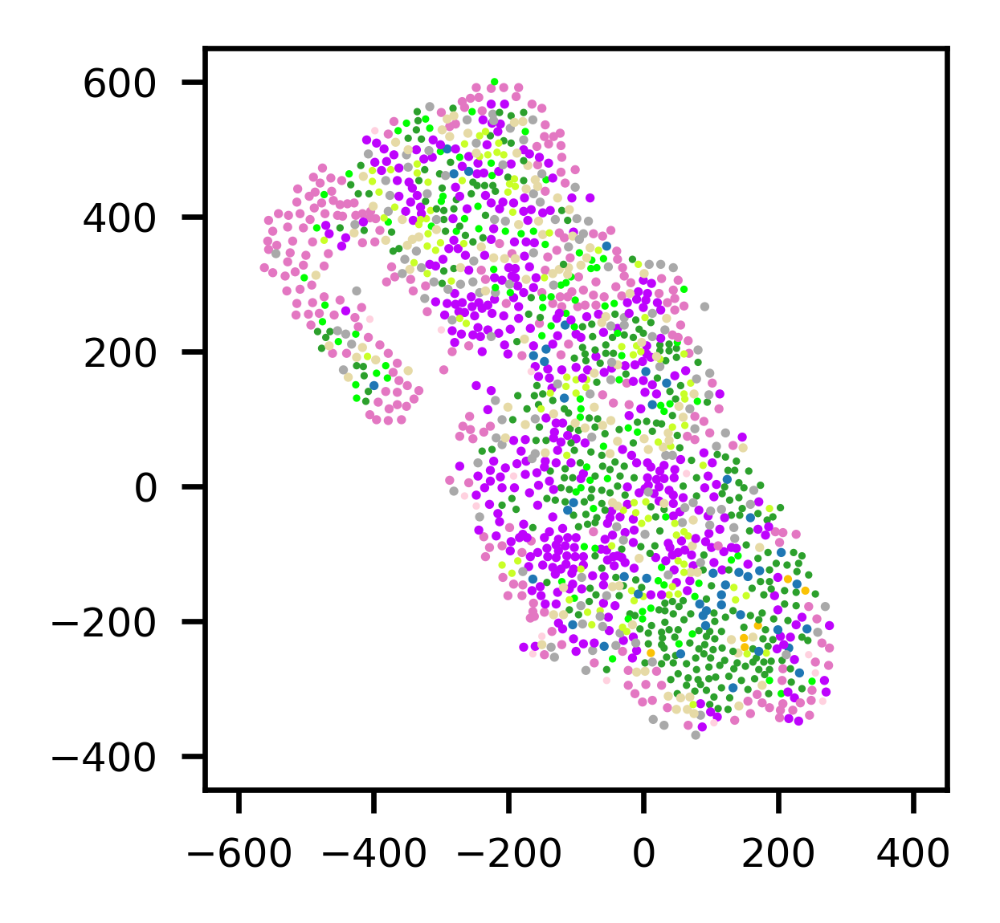

In [10]:
df = pd.read_csv(f"{path_to_mihc}/in_silico_106.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1100 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

fig, ax = plt.subplots(figsize=(2, 2), dpi=600)
df.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-650, 450), ylim=(-450, 650), linewidths=0.5, colorbar=False)

ax.set(xlabel="", ylabel="")
ax.set_aspect(1)

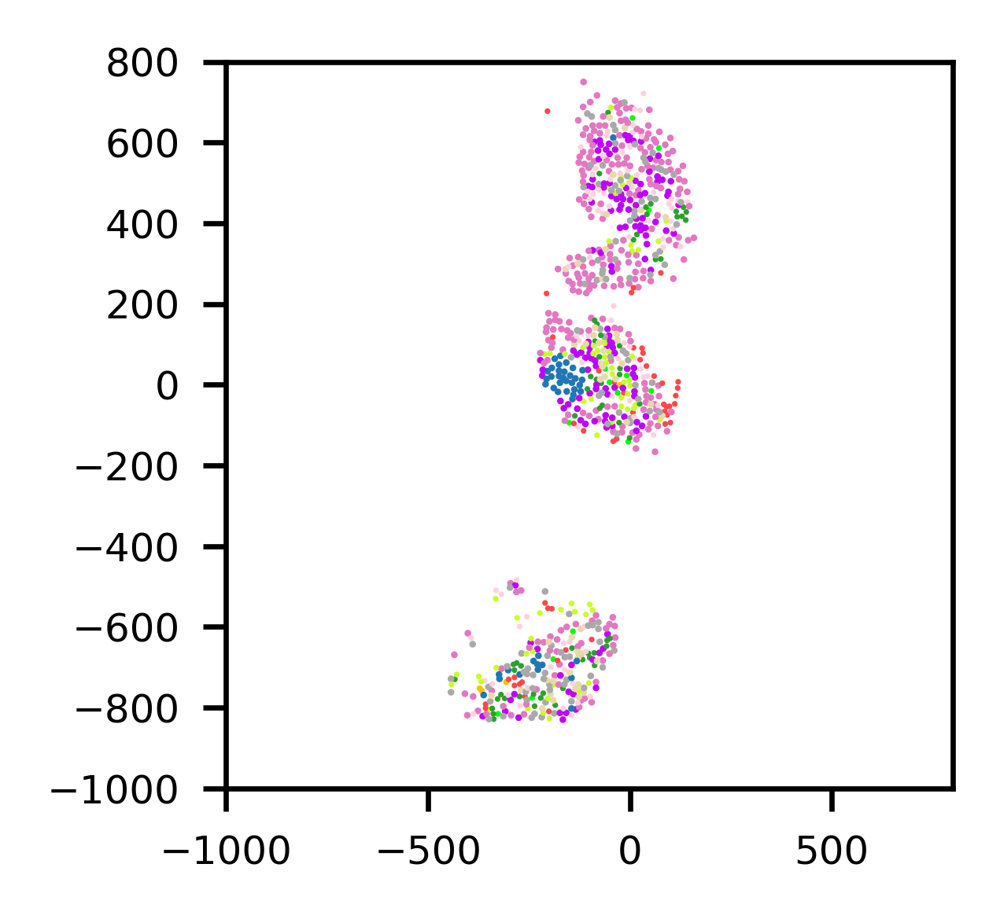

In [11]:
df = pd.read_csv(f"/{path_to_mihc}/in_silico_114.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1800 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

fig, ax = plt.subplots(figsize=(2, 2), dpi=600)
df.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-1000, 800), ylim=(-1000, 800), linewidths=0.5, colorbar=False)

ax.set(xlabel="", ylabel="")
ax.set_aspect(1)

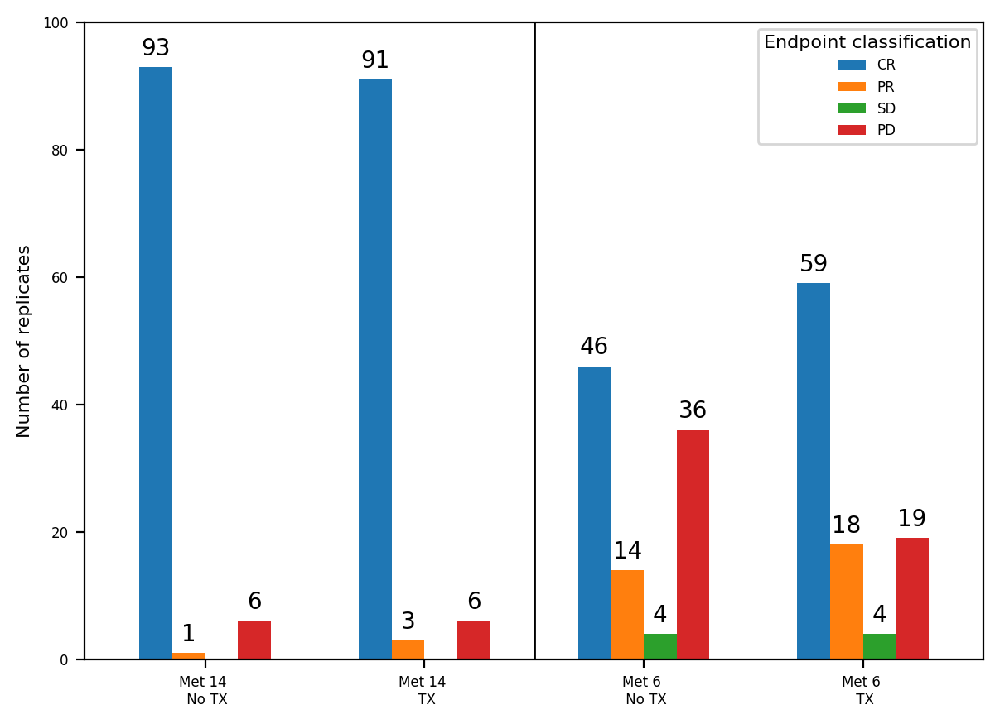

In [12]:
mets = [6, 14]
num_replicates = 100

highrep_results = []
for met in mets:
    for j in range(num_replicates):
        path = os.path.join(path_to_simulations, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        tx_path = os.path.join(path_to_simulations, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        data = pd.read_csv(path, header=0)
        tx_data = pd.read_csv(tx_path, header=0)
        highrep_results.append([data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "no tx"])
        highrep_results.append([tx_data["c"].tolist()[-1], tx_data["c"].tolist()[0], f"Met {met}", "tx"])

highrep_results = pd.DataFrame(highrep_results, columns=["Final cancer", "Initial cancer", "Met", "Treatment"])
highrep_results["Normalized no. cancer"] = highrep_results["Final cancer"].astype(float) / highrep_results["Initial cancer"].astype(float)
highrep_results["Normalized sqrt(no. cancer)"] = np.sqrt(highrep_results["Final cancer"].astype(float)) / np.sqrt(highrep_results["Initial cancer"].astype(float))

intervals = pd.cut(highrep_results['Normalized no. cancer'], bins=[-1, 0, 0.7, 1.2, 15], labels=['CR', 'PR', 'SD', 'PD'], right=True)
highrep_results["intervals"] = pd.cut(highrep_results['Normalized no. cancer'], bins=[-1, 0, 0.7, 1.2, 15], labels=['CR', 'PR', 'SD', 'PD'], right=True)
highrep_results["intervals"] = highrep_results["intervals"].astype('category')

highrep_results.pivot_table(index=intervals, columns=['Met', 'Treatment'], values='Normalized no. cancer', aggfunc='count', observed=False)

fig, ax = plt.subplots(1, 1, figsize=(7, 5), dpi=200)
highrep_results.pivot_table(index=intervals, columns=['Met', 'Treatment'], values='Normalized no. cancer', aggfunc='count', observed=False).transpose().plot.bar(ax=ax, width=0.6)
for i in range(len(ax.containers)):
    ax.bar_label(ax.containers[i], padding=3, fmt=lambda x: int(x) if x > 0 else '')
ax.set(ylim=(0, 100), xlabel="", ylabel="Number of replicates")
ax.tick_params(axis='x', rotation=0)
ax.set_xticklabels(['Met 14 \n No TX', 'Met 14 \n TX', 'Met 6 \n No TX', 'Met 6 \n TX'])
ax.vlines(1.5, 0, 100, "k", lw=1)
ax.legend().set_title('Endpoint classification')

The below cell generates **Sup. Fig. S3B**, which shows the cancer trajectories for these two metastases and their endpoint classifications.

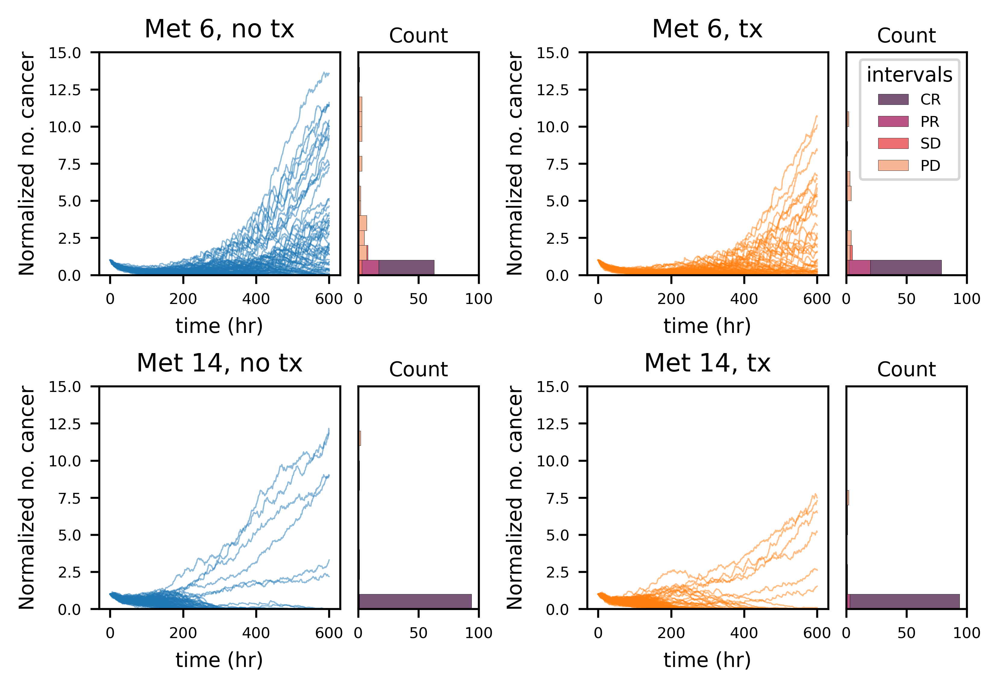

In [13]:
met6_full_notx = retrieve_ts(path_to_simulations + "/mIHC_106", num_replicates=100)
met6_full_tx = retrieve_ts(path_to_simulations + "/mIHC_106_tx", num_replicates=100)
met14_full_notx = retrieve_ts(path_to_simulations + "/mIHC_114", num_replicates=100)
met14_full_tx = retrieve_ts(path_to_simulations + "/mIHC_114_tx", num_replicates=100)

fig = plt.figure(figsize=(6, 4), dpi=600)
max_x = 100
max_y = 15

grid_l = gridspec.GridSpec(2, 2, left=0.1, right=0.45, wspace=0.1, hspace=0.5, width_ratios=[2,1])
grid_r = gridspec.GridSpec(2, 2, left=0.55, right=0.9, wspace=0.1, hspace=0.5, width_ratios=[2,1])

ax00 = fig.add_subplot(grid_l[0,0])
ax01 = fig.add_subplot(grid_l[0,1])
ax10 = fig.add_subplot(grid_l[1,0])
ax11 = fig.add_subplot(grid_l[1,1])

ax02 = fig.add_subplot(grid_r[0,0])
ax03 = fig.add_subplot(grid_r[0,1])
ax12 = fig.add_subplot(grid_r[1,0])
ax13 = fig.add_subplot(grid_r[1,1])

# Plot traces
(met6_full_notx["c"] / 44).plot.line(lw=0.5, color="tab:blue", legend=False, ax=ax00, alpha=0.5)
(met6_full_tx["c"] / 44).plot.line(lw=0.5, color="tab:orange", legend=False, ax=ax02, alpha=0.5)
ax00.set(title="Met 6, no tx", xlabel="time (hr)", ylabel="Normalized no. cancer", ylim=(0, max_y))
ax02.set(title="Met 6, tx", xlabel="time (hr)", ylabel="Normalized no. cancer", ylim=(0, max_y))

(met14_full_notx["c"] / 43).plot.line(lw=0.5, color="tab:blue", legend=False, ax=ax10, alpha=0.5)
(met14_full_tx["c"] / 43).plot.line(lw=0.5, color="tab:orange", legend=False, ax=ax12, alpha=0.5)
ax10.set(title="Met 14, no tx", xlabel="time (hr)", ylabel="Normalized no. cancer", ylim=(0, max_y))
ax12.set(title="Met 14, tx", xlabel="time (hr)", ylabel="Normalized no. cancer", ylim=(0, max_y))

# Plot distributions
kwargs = {"y":"Normalized no. cancer", "binwidth":1, "binrange":(0, max_y), "multiple":"stack", "legend":True, "palette":"rocket", "hue":"intervals", "lw":.1}
sns.histplot(highrep_results[(highrep_results["Met"] == "Met 6") * (highrep_results["Treatment"] == "no tx")], ax=ax01, **kwargs)
sns.histplot(highrep_results[(highrep_results["Met"] == "Met 6") * (highrep_results["Treatment"] == "tx")], ax=ax03, **kwargs)
sns.histplot(highrep_results[(highrep_results["Met"] == "Met 14") * (highrep_results["Treatment"] == "no tx")], ax=ax11, **kwargs)
sns.histplot(highrep_results[(highrep_results["Met"] == "Met 14") * (highrep_results["Treatment"] == "tx")], ax=ax13, **kwargs)

for ax in [ax01, ax11, ax03, ax13]:
    ax.set(ylabel="", xlim=(0, max_x), ylim=(0, max_y))
    # ax.bar_label(ax.containers[0], padding=2, fmt=lambda x: int(x) if x > 0 else '')
    ax.get_yaxis().set_visible(False)
    ax.xaxis.set_label_position('top') 

ax01.get_legend().remove()
ax11.get_legend().remove()
ax13.get_legend().remove()

## Supplementary Figure S4 -- Exhaustion dynamics in CD8+ T cells illustrate the effect of treatment on single-cell behavior.

In [14]:
# These are the summary statistics
path = f'{path_to_precomputed}/all_exhaustion_scores_07222026.feather'
df_joined = pd.read_feather(path)
df_joined["CV Non-Rapid"] = df_joined["Std Non-Rapid"] / df_joined["Mean Non-Rapid"]

# These are the raw scores used to plot the distributions
with open(f'{path_to_precomputed}/exh_scores_notx_07222026.pkl', "rb") as file:
    scores_notx = pickle.load(file)

with open(f'{path_to_precomputed}/exh_scores_tx_07222026.pkl', "rb") as file:
    scores_tx = pickle.load(file)

# Make the mets ordered by subtype
met_order = [7, 8, 17, 30, 34, 40, 43, # TX effect
             6, 14, # Bifurcators
             28, # No TX effect, SD
             0, 12, 13, 22, 23, 25, 32, 42, 45] # No TX effect, PD
ordered_met = pd.api.types.CategoricalDtype(categories=met_order, ordered=True)
df_joined["Met"] = df_joined["Met"].astype(ordered_met)

df_join_tx = df_joined[df_joined["Treatment"] == "tx"]
df_join_notx = df_joined[df_joined["Treatment"] == "no tx"]

The below cell generates **Sup. Fig. 4B**, which shows the distribution of CD8+ T cell p(kill) exhaustion scores.

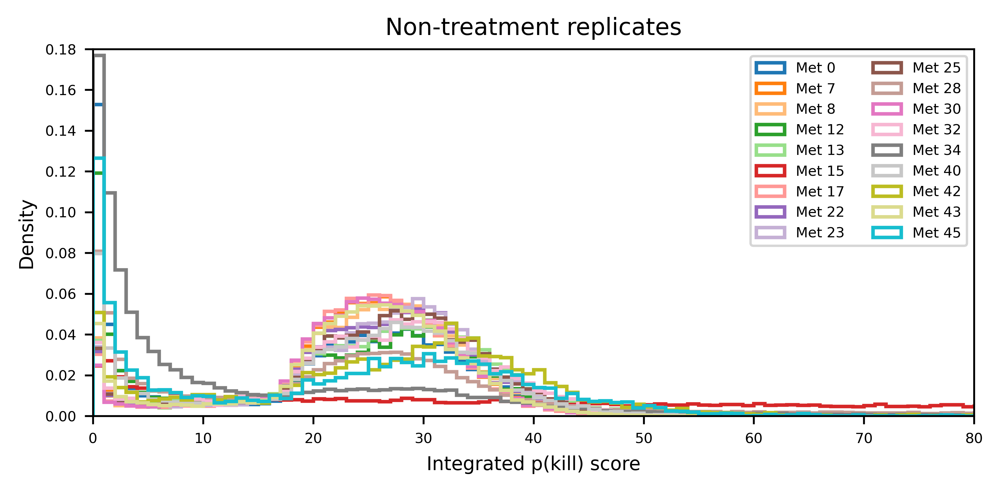

In [15]:
# Separate responders and non-responders
tab20 = mcolors.ListedColormap(plt.colormaps['tab20'].colors)
mets = [100, 106, 107, 108, 112, 113, 115, 117, 122, 123, 125, 128, 130, 132, 134, 140, 142, 143, 145]
responders = [107, 108, 117, 130, 134, 140, 143]
nonresponders = [100, 112, 113, 122, 123, 125, 128, 132, 142, 145]

fig, ax = plt.subplots(1, 1, figsize=(6, 3), dpi=600)

for i in range(19):
    if mets[i] not in [106, 114]:
        ax.hist(np.concat(scores_notx[i]), label=f"Met {mets[i] - 100}", bins=200, range=(0, 200), color=tab20(i), histtype='step', density=True, cumulative=False, lw=1.5)
    
ax.set(xlim=(0, 80), ylim=(0, 0.18), ylabel="Density", xlabel="Integrated p(kill) score", title="Non-treatment replicates")
ax.legend(ncols=2)

fig.tight_layout()

The below cell generates **Sup. Fig. 4A**, which shows an example of CD8+ T cell p(kill) exhaustion trajectories.

[Text(10.333333333333314, 0.5, 'Cell index (% of total)'),
 Text(0.5, 58.33333333333329, 'Hours from birth'),
 Text(0.5, 1.0, 'Met 0')]

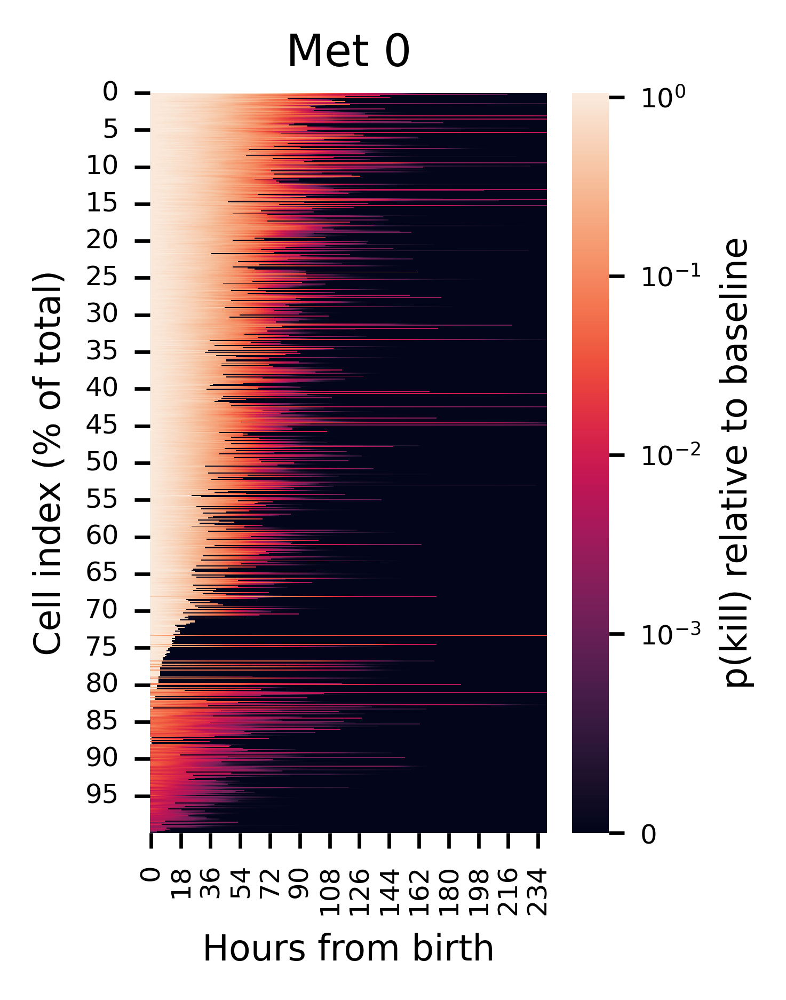

In [16]:
# Plot an example heatmap
from matplotlib.colors import SymLogNorm

# data = extract_exhaustion_trajectories(path_to_simulations + "/mIHC_100/set_0")
with open(f"{path_to_precomputed}/exh_traj_example.pkl", "rb") as f:
    data = pickle.load(f)

exh_data = align_on_exh(data)
exh_data = np.pad(exh_data[0], ((0, 0), (0, 601 - exh_data[0].shape[1])))
idx = np.argsort(np.sum(exh_data, axis=1))
exh_data = exh_data[idx]

fig, ax = plt.subplots(figsize=(2, 3), dpi=600)
sns.heatmap(exh_data[::-1][:, 0:240], ax=ax, norm=SymLogNorm(linthresh=.001), cbar_kws={'label': 'p(kill) relative to baseline', 'orientation':'vertical'})
ax.set_yticks(np.arange(0, len(exh_data), len(exh_data)/20), labels=np.arange(0, 100, 5))
ax.set(ylabel="Cell index (% of total)", xlabel="Hours from birth", title="Met 0")

The below cell generates **Sup. Fig S4C**, which shows the distributions of median non-rapid integrated p(kill) scores for CD8+ T cell populations in metastases, with and without simulated dual ICI.

/tmp/SLURM_6780182/ipykernel_3468985/1329983645.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset["Met"] = subset["Met"].astype('category')
/tmp/SLURM_6780182/ipykernel_3468985/1329983645.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  subset['Met'] = subset['Met'].cat.reorder_categories(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Met 0_no tx vs. Met 0_tx: t-test independent samples, P_val:5.260e-27 t=-2.233e+01
Met 7_no tx vs. Met 7_tx: t-test independent samples, P_val:1.282e-37 t=-3.826e+01
Met 8_no tx vs. Met 8_tx: t-test independent samples, P_val:5.545e-30 t=-2.606e+01
Met 17_no tx vs. Met 17_tx: t-test independent samples, P_val:3.606e-31 t=-2.769e+01
Met 28_no tx vs. Met 28_tx: t-test independent samples, P_val:1.059e-03 t=-3.486e+00
Met 30_no tx vs. Met 30_tx: t-test independent samples, P_val:2.782e-33 t=-3.082e+01
Met 43_no tx vs. Met 43_tx: t-test independent samples, P_val:2.080e-35 t=-3.428e+01
Met 22_no tx vs. Met 22_tx: t-test independent samples, P_val:1.444e-20 t=-1.573e+01
Met 45_no tx vs. Met 45_tx: t-test independent samples, P_val:1.374e-05 t=-4.843e+00
Met 32_no tx vs. Met 32_tx: t-test independent sa

[Text(444.8333333333333, 0.5, 'Median non-rapid integrated p(kill)')]

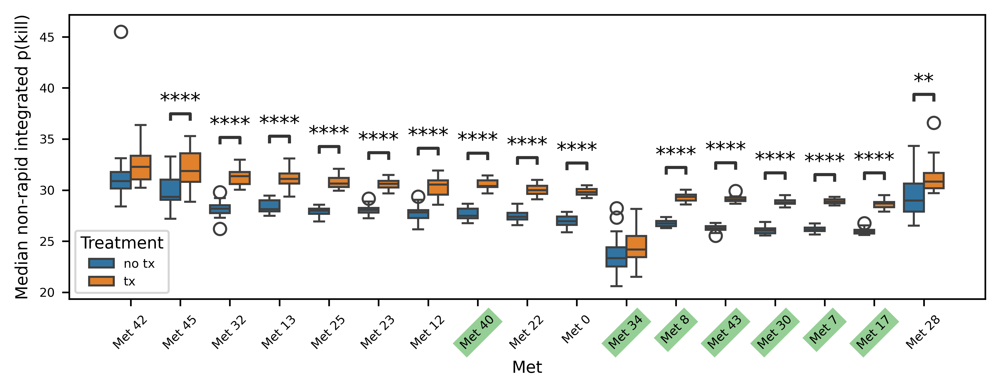

In [17]:
ttest_comp = [(("Met " + str(met), "no tx"), ("Met " + str(met), "tx")) for met in df_joined.Met.unique()[(df_joined.Met.unique() != 6) & (df_joined.Met.unique() != 14)]]

fig, ax = plt.subplots(figsize=(8, 2.5), dpi=600)
df_joined["Met"] = ["Met " + str(item) for item in df_joined["Met"]]
subset = df_joined[~df_joined["Met"].isin(["Met 6", "Met 14"])]
subset["Met"] = subset["Met"].astype('category')
subset['Met'] = subset['Met'].cat.reorder_categories(
    ['Met 42', 'Met 45', 'Met 32', 'Met 13', 'Met 25', 'Met 23', 'Met 12', 'Met 40', 'Met 22', 'Met 0', 'Met 34', 
     'Met 8', 'Met 43', 'Met 30', 'Met 7', 'Met 17', 'Met 28'])

sns.boxplot(subset, x="Met", y="Median Non-Rapid", hue="Treatment", ax=ax)

annotator1 = Annotator(ax=ax, data=subset, pairs=ttest_comp, x="Met", y="Median Non-Rapid", hue="Treatment")
annotator1.configure(test = 't-test_ind', text_format = 'star', hide_non_significant=True)
annotator1.apply_test().annotate()

ax.tick_params(axis='x', rotation=45)
classes = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0]
classes_to_color = {0:'none', 1:'tab:green'}
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

ax.set(ylabel="Median non-rapid integrated p(kill)")

## Figure 4 -- Visualizing heterogeneity in metastasis spatial structure via low-dimensional representations of pairwise interactions between cell types.

The below cells generate spatial plots & other components used in **Figure 4A** to illustrate the analysis workflow for this figure.

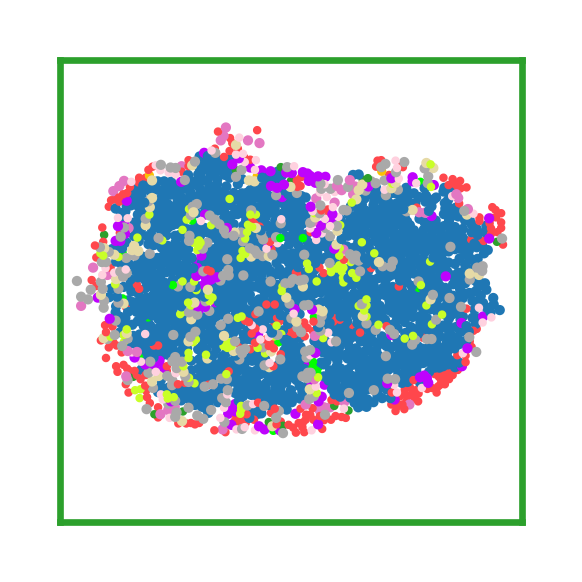

In [18]:
df = pd.read_csv(f"{path_to_mihc}/in_silico_117.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1300 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

fig, ax = plt.subplots(figsize=(1, 1), dpi=600)
df.plot.scatter('x', 'y', ax=ax, s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-400, 900), ylim=(-900, 400), linewidths=0.5, colorbar=False)

ax.set(xlabel="", ylabel="")
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_color('tab:green')
ax.set_aspect(1)

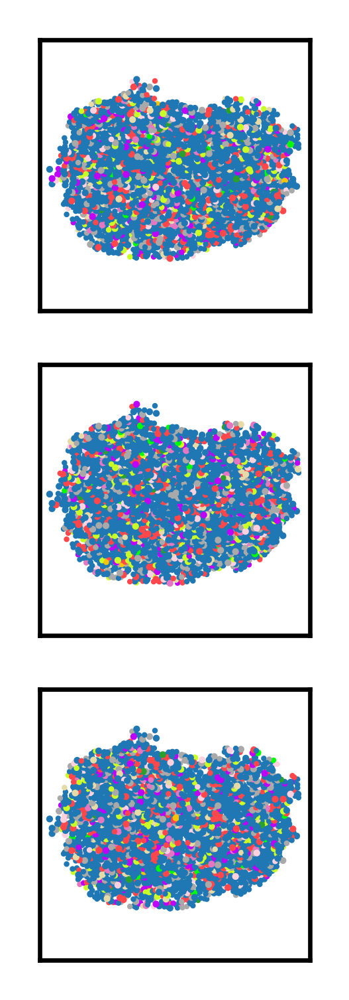

In [19]:
df = pd.read_csv(f"{path_to_mihc}/in_silico_117.csv", usecols=[1,2,3,4], names=["x", "y", "state", "area"])

scale = (2 / (1300 * 2 + 1) * 300.) ** 2
df["s_scaled"] = scale * np.sqrt(df["area"]/np.pi)
df["state"] = df["state"].map(adjust_state)

# Shuffle the image
fig, ax = plt.subplots(3, 1, figsize=(1,3), dpi=600)

seed = 283798029347189347591394185743451
for i in range(3):
    rng1 = np.random.default_rng(seed)
    df["state"] = rng1.permutation(df['state'].values)
    df.plot.scatter('x', 'y', s="s_scaled", c = "state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, xlim=(-400, 900), ylim=(-900, 400), linewidths=0.5, colorbar=False, ax=ax[i])
    seed = ((seed << i) + seed)
    
for axis in ax:
    axis.set(xlabel="", ylabel="")
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_aspect(1)

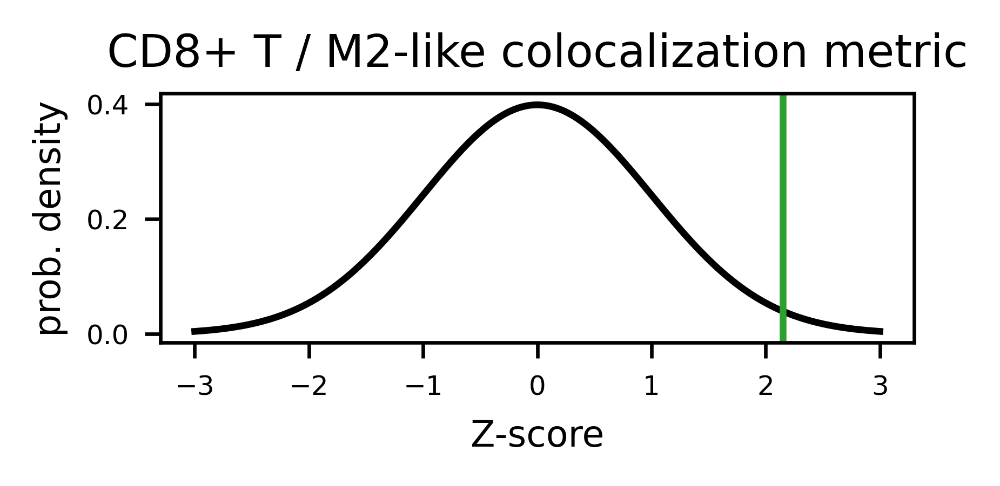

In [20]:
# Plot a normal distribution & an outlier
fig, ax = plt.subplots(figsize=(3, 1), dpi=600)
x = np.linspace(-3, 3, 1000)
y = stats.norm.pdf(x, 0, 1)

ax.plot(x, y, c="black")
ax.set(xlabel="Z-score", ylabel="prob. density", title="CD8+ T / M2-like colocalization metric")
ax.axvline(2.15, color="tab:green")

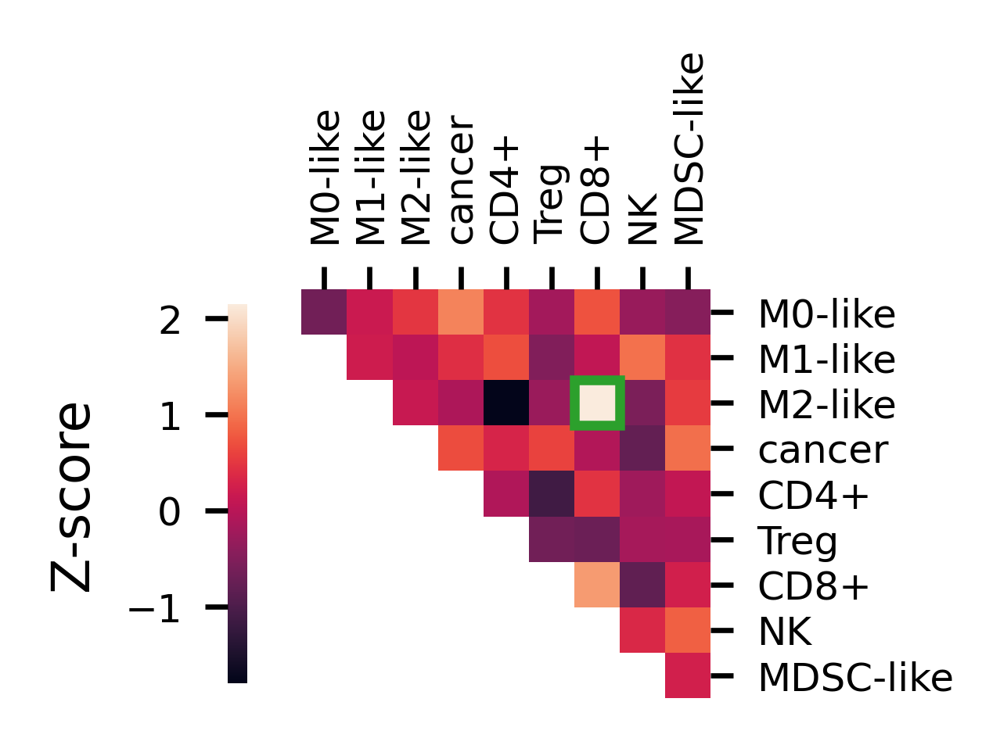

In [21]:
from matplotlib.patches import Rectangle

rng = np.random.default_rng(seed=124776213759812375)
random_mat = rng.standard_normal((9, 9))
random_mat = 0.5 * (random_mat + random_mat.T)
random_mat[6, 2] = 2.15
random_mat[2, 6] = 2.15

labels = ["M0-like", "M1-like", "M2-like", "cancer", "CD4+", "Treg", "CD8+", "NK", "MDSC-like"]
fig, ax = plt.subplots(figsize=(1.5, 1.5), dpi=600)
mask = np.tril(random_mat, k=-1)
sns.heatmap(random_mat, ax=ax, xticklabels=True, yticklabels=True, cbar_kws={'label':'Z-score', 'location':'left', 'shrink':0.7}, mask=mask)
ax.add_patch(
    Rectangle((6, 2), 1, 1, fill=False, edgecolor="tab:green", lw=1.5)
)
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels, rotation=0)
ax.xaxis.tick_top()
ax.yaxis.tick_right()
ax.set_aspect(1)

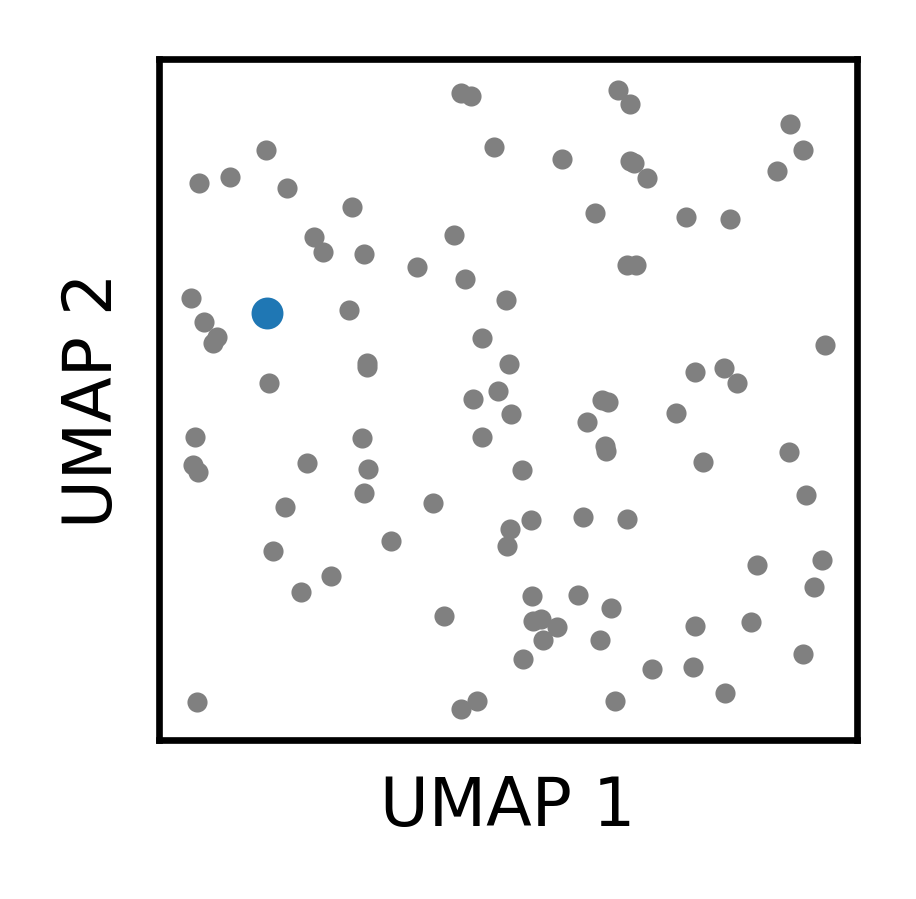

In [22]:
fig, ax = plt.subplots(figsize=(1.5, 1.5), dpi=600)

rng = np.random.default_rng(seed=124776213759812375)
random_points = rng.uniform(-10, 10, size=(100,2))
ax.scatter(random_points[2:,0], random_points[2:,1], s=2, color="grey")
ax.scatter(random_points[1,0], random_points[1,1], s=8, color="tab:blue")
ax.set(xlabel="UMAP 1", ylabel="UMAP 2")
ax.set_xticks([])
ax.set_yticks([])
ax.set_aspect(1)

The below cell generates the co-localization matrices.

In [23]:
# Use this cell to import the pre-generated data
path = f"{path_to_precomputed}/processed_zscoremats_perm1000.feather"
projected_df = pd.read_feather(path)

# This extracts and re-flattens the UT portion of the matrix
projected_df["UT_vect"] = projected_df.vect.apply(lambda x: x.reshape((9,9))[np.triu_indices_from(np.ones((9,9)))].flatten())
all_data = np.array(projected_df.UT_vect.to_list())

The below cell generates **Figure 4B**, which shows the co-localization matrices projected into 2D space via UMAP.

/home1/kingtyle/.local/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


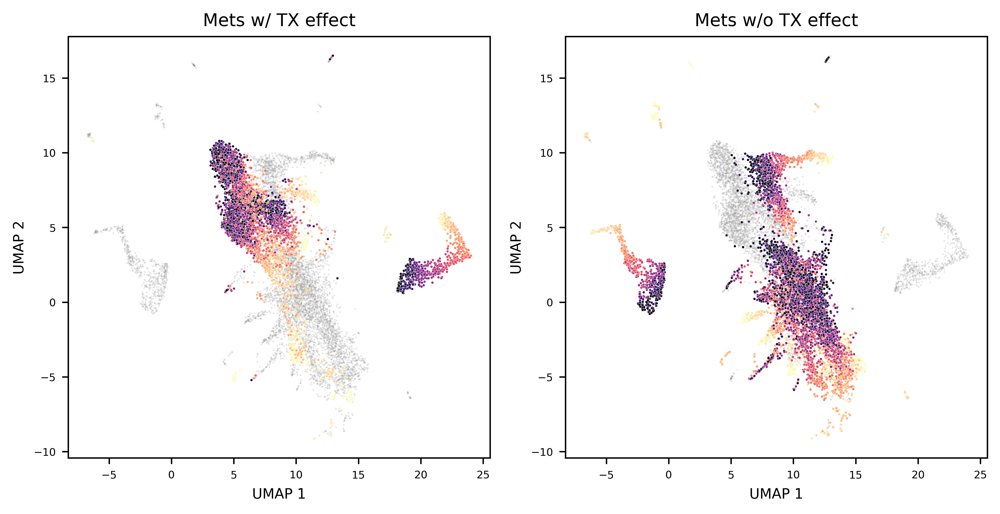

In [24]:
# These UMAPs are better for visualization
umap = UMAP(n_neighbors=10, min_dist=0.5, random_state=42)
new_proj = umap.fit_transform(all_data)
projected_df["UMAP_new1"] = new_proj[:,0]
projected_df["UMAP_new2"] = new_proj[:,1]
tab20cmap = mcolors.ListedColormap(plt.colormaps['tab20'].colors[:-1])
nonbif_cmap = [tab20cmap(i) for i in [0, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]]

# Plot the projection
responders = [107, 108, 117, 130, 134, 140, 143]
r_idx = [2, 3, 7, 12, 14, 15, 17]
nonresponders = [100, 112, 113, 122, 123, 125, 128, 132, 142, 145]
nr_idx = [0, 4, 5, 8, 9, 10, 11, 13, 16, 18]
r_cmap = [tab20cmap(i) for i in r_idx]
nr_cmap = [tab20cmap(i) for i in nr_idx]

fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=600)

# Plot the other dataset
sns.scatterplot(projected_df[(projected_df["type"] == "no_tx") * (projected_df["met"].isin(responders))], x="UMAP_new1", y="UMAP_new2", c="tab:gray", ax=ax[1], s=1, alpha=0.2, legend=False)
sns.scatterplot(projected_df[(projected_df["type"] == "no_tx") * (projected_df["met"].isin(nonresponders))], x="UMAP_new1", y="UMAP_new2", c="tab:gray", ax=ax[0], s=1, alpha=0.2, legend=False)

# Plot the focus dataset
sns.scatterplot(projected_df[(projected_df["type"] == "no_tx") * (projected_df["met"].isin(responders))], x="UMAP_new1", y="UMAP_new2", hue="hour", palette="magma_r", ax=ax[0], s=2, legend=False)
sns.scatterplot(projected_df[(projected_df["type"] == "no_tx") * (projected_df["met"].isin(nonresponders))], x="UMAP_new1", y="UMAP_new2", hue="hour", palette="magma_r", ax=ax[1], s=2, legend=False)

ax[0].set(title = "Mets w/ TX effect", xlabel="UMAP 1", ylabel="UMAP 2")
ax[1].set(title = "Mets w/o TX effect", xlabel="UMAP 1", ylabel="UMAP 2")
ax[0].set_box_aspect(1)
ax[1].set_box_aspect(1)

fig.tight_layout()

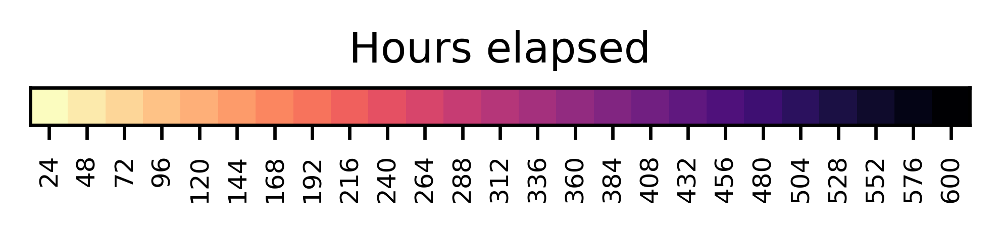

In [25]:
# Create a colorbar that associates each color w/ the associated time stamp
days = np.arange(24, 624, 24)
magma_rcmap = mcolors.ListedColormap(plt.colormaps['magma_r'](np.linspace(0, 1, len(days))))
fig, ax = plt.subplots(figsize=(4, 1), dpi=600)
ax.imshow([np.arange(len(days))], cmap=magma_rcmap)
ax.set_xticks(np.arange(len(days)), days, rotation=90)
ax.set(title="Hours elapsed")
ax.yaxis.set_visible(False)

## Figure 5 -- Analysis of pairwise cell-cell interactions within the tumor microenvironment.

This also generates **Supplementary Figure S5**, which shows alternative approaches for logistic regression using multiplicative combinations of interaction ratios.

In [26]:
# If you have already generated the data, load it
merged_df_notx = pd.read_feather(f'{path_to_precomputed}/all_spatial_scores_notx_06292026.feather')

In [27]:
# Separate responders and non-responders
tab20 = mcolors.ListedColormap(plt.colormaps['tab20'].colors)
responders = [107, 108, 117, 130, 134, 140, 143]
nonresponders = [100, 112, 113, 122, 123, 125, 128, 132, 142, 145]
r_idx = [2, 3, 7, 12, 14, 15, 17]
nr_idx = [0, 4, 5, 8, 9, 10, 11, 13, 16, 18]
r_cmap = [tab20(i) for i in r_idx]
nr_cmap = [tab20(i) for i in nr_idx]

The following cell generates the IR timeseries plots shown in **Figure 5B**.

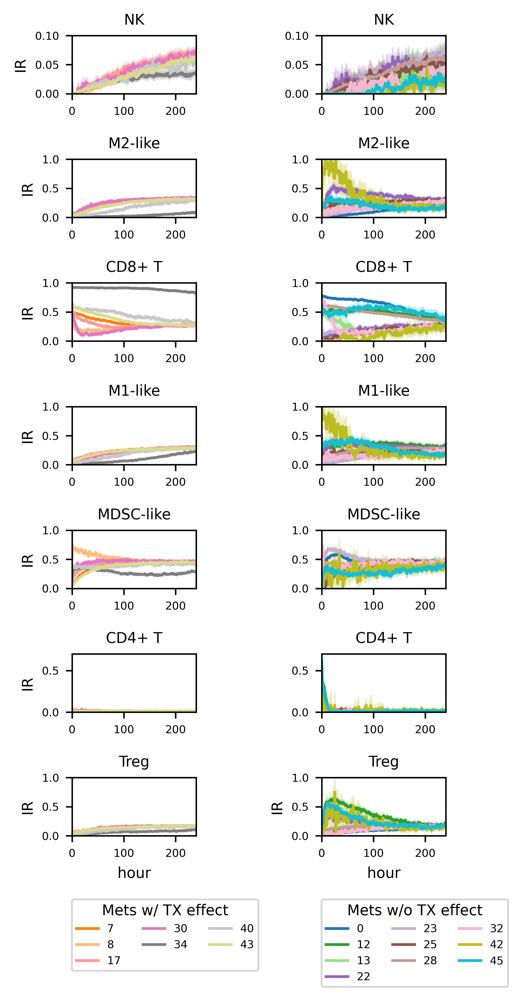

In [28]:
fig, ax = plt.subplots(7, 2, figsize=(4, 8), dpi=600)

# Temporarily make titles smaller
plt.rcParams.update({'axes.titlesize': 8})

# Anti-tumor interactions (NK, CD8+ T, M1-like, CD4+ T)
sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="nk_supratio", hue="met", palette=r_cmap, ax=ax[0,0], legend=False)
ax[0,0].set(xlim=(0, 240), ylim=(0, 0.1), title=r"NK", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="nk_supratio", hue="met", palette=nr_cmap, ax=ax[0,1], legend=False)
ax[0,1].set(xlim=(0, 240), ylim=(0, 0.1), title=r"NK", xlabel="", ylabel="")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="cd8_supratio", hue="met", palette=r_cmap, ax=ax[2,0], legend=False)
ax[2,0].set(xlim=(0, 240), ylim=(0, 1), title=r"CD8+ T", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="cd8_supratio", hue="met", palette=nr_cmap, ax=ax[2,1], legend=False)
ax[2,1].set(xlim=(0, 240), ylim=(0, 1), title=r"CD8+ T", xlabel="", ylabel="")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="m1_supratio", hue="met", palette=r_cmap, ax=ax[3,0], legend=False)
ax[3,0].set(xlim=(0, 240), ylim=(0, 1), title=r"M1-like", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="m1_supratio", hue="met", palette=nr_cmap, ax=ax[3,1], legend=False)
ax[3,1].set(xlim=(0, 240), ylim=(0, 1), title=r"M1-like", xlabel="", ylabel="")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="th_supratio", hue="met", palette=r_cmap, ax=ax[5,0], legend=False)
ax[5,0].set(xlim=(0, 240), ylim=(0, .7), title=r"CD4+ T", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="th_supratio", hue="met", palette=nr_cmap, ax=ax[5,1], legend=False)
ax[5,1].set(xlim=(0, 240), ylim=(0, .7), title=r"CD4+ T", xlabel="", ylabel="")

# Pro-tumor interactions (MDSC-like, M2-like, Treg)
sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="mdsc_supratio", hue="met", palette=r_cmap, ax=ax[4,0], legend=False)
ax[4,0].set(xlim=(0, 240), ylim=(0, 1), title=r"MDSC-like", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="mdsc_supratio", hue="met", palette=nr_cmap, ax=ax[4,1], legend=False)
ax[4,1].set(xlim=(0, 240), ylim=(0, 1), title=r"MDSC-like", xlabel="", ylabel="")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="m2_supratio", hue="met", palette=r_cmap, ax=ax[1,0], legend=False)
ax[1,0].set(xlim=(0, 240), ylim=(0, 1), title=r"M2-like", xlabel="", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="m2_supratio", hue="met", palette=nr_cmap, ax=ax[1,1], legend=False)
ax[1,1].set(xlim=(0, 240), ylim=(0, 1), title=r"M2-like", xlabel="", ylabel="")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(responders)], x="hour", y="treg_supratio", hue="met", palette=r_cmap, ax=ax[6,0])
ax[6,0].legend(loc="upper center", bbox_to_anchor=(0.75, -1), ncol=3, title="Mets w/ TX effect")
for t, l in zip(ax[6,0].legend_.texts, [met - 100 for met in responders]):
    t.set_text(l)
ax[6,0].set(xlim=(0, 240), ylim=(0, 1), title=r"Treg", ylabel="IR")

sns.lineplot(merged_df_notx[merged_df_notx["met"].isin(nonresponders)], x="hour", y="treg_supratio", hue="met", palette=nr_cmap, ax=ax[6,1])
ax[6,1].legend(loc="upper center", bbox_to_anchor=(0.75, -1), ncol=3, title="Mets w/o TX effect")
for t, l in zip(ax[6,1].legend_.texts, [met - 100 for met in nonresponders]):
    t.set_text(l)
ax[6,1].set(xlim=(0, 240), ylim=(0, 1), title=r"Treg", ylabel="IR")

fig.tight_layout()

# Reset default title size
plt.rcParams.update({'axes.titlesize': 10})

The following cell runs a logistic regression then generates plots showing the AUROC curve (**Figure 5C**) and logistic regression coefficients (**Figure 5D**).

For day 600:
Accuracy:  0.8258823529411765
Balanced accuracy:  0.8271428571428572 



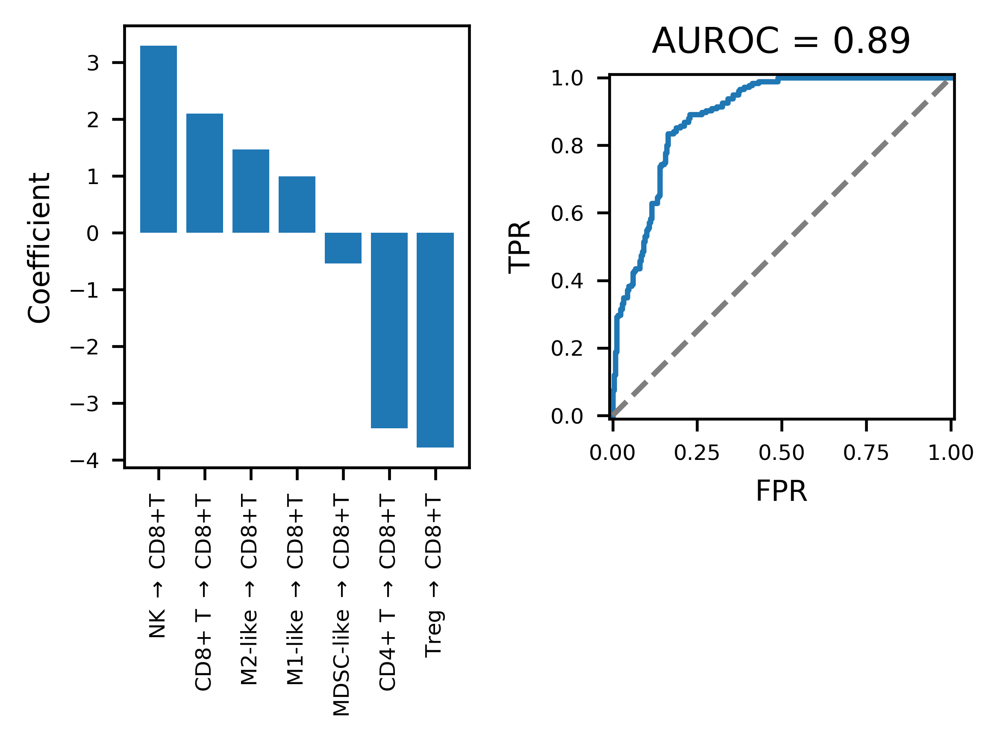

In [29]:
# Run the non-interaction regression
fig, ax = plt.subplots(1, 2, figsize=(4, 3), dpi=600, gridspec_kw={'width_ratios':[1, 1]})

score_until = 24*20
score_df = merged_df_notx[merged_df_notx["hour"] < score_until].pivot_table(index=["set", "met"], aggfunc="sum")
score_df = pd.DataFrame(score_df.to_records()).drop(columns=["hour", "set", "CD8:cancer", "met", "infiltration", "threat"])
X_1 = score_df.values
X_1 = MinMaxScaler().fit_transform(X_1)
y = np.array(25 * [0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0]) # This is the classification of each  w/ 6 and 14 removed

# Do logistic regression
clf_1 = LogisticRegression(solver='liblinear', random_state=0, max_iter=1000).fit(X_1, y)
print(f"For day {600}:")
print("Accuracy: ", clf_1.score(X_1, y))
print("Balanced accuracy: ", balanced_accuracy_score(y, clf_1.predict(X_1)), "\n")

# Extract features
feature_importances = clf_1.coef_
num_features = len(feature_importances.reshape(-1))

waterfall_order = np.argsort(feature_importances.reshape(-1))[::-1]
label_to_name = {
    "cd8_supratio" : r"CD8+ T $\rightarrow$ CD8+T",
    "m1_supratio" : r"M1-like $\rightarrow$ CD8+T",
    "m2_supratio" : r"M2-like $\rightarrow$ CD8+T",
    "mdsc_supratio" : r"MDSC-like $\rightarrow$ CD8+T",
    "nk_supratio" : r"NK $\rightarrow$ CD8+T",
    "th_supratio" : r"CD4+ T $\rightarrow$ CD8+T",
    "treg_supratio" : r"Treg $\rightarrow$ CD8+T",
    "threat" : r"Cancer vulnerability"}

# Plot
ax[0].bar(range(num_features), height = np.sort(feature_importances.reshape(-1))[::-1])
ax[0].set_xticks(range(num_features), [label_to_name[label] for label in score_df.columns[waterfall_order]], rotation=90)
ax[0].set(ylabel="Coefficient")

RocCurveDisplay.from_estimator(clf_1, X_1, y, ax=ax[1])
ax[1].plot([0, 1], [0, 1], c="tab:gray", ls="--")
ax[1].set(xlabel="FPR", ylabel="TPR", title=f"AUROC = {roc_auc_score(y, clf_1.predict_proba(X_1)[:,1]):.2f}")
ax[1].legend_.remove()

fig.tight_layout()

This cell runs an alternative logistic regression then plots the coefficients shown in **Sup. Fig. 5A**.

Accuracy:  0.8352941176470589
Balanced accuracy:  0.8351428571428572


[Text(0, 0.5, 'Coefficient')]

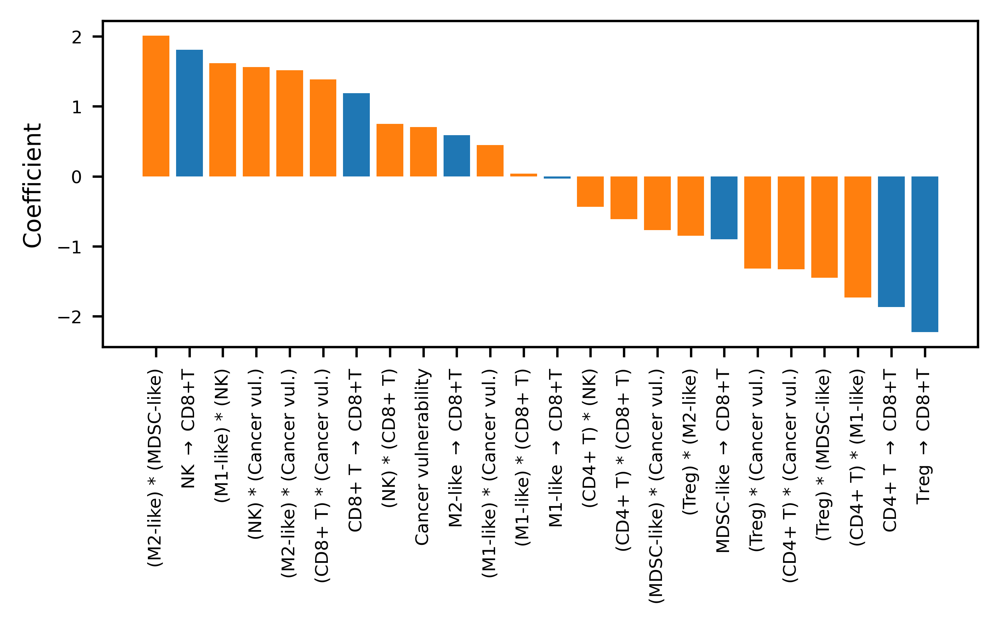

In [31]:
# Run with select interactions
fig, ax = plt.subplots(figsize=(16/3, 2), dpi=600)

permitted_interactions = [["cd8_supratio", "threat"],
                          ["nk_supratio", "threat"],
                          ["nk_supratio", "cd8_supratio"],
                          ["m1_supratio", "threat"],
                          ["m1_supratio", "cd8_supratio"],
                          ["m1_supratio", "nk_supratio"],
                          ["th_supratio", "threat"],
                          ["th_supratio", "cd8_supratio"],
                          ["th_supratio", "nk_supratio"],
                          ["th_supratio", "m1_supratio"],
                          ["mdsc_supratio", "threat"],
                          ["m2_supratio", "threat"],
                          ["m2_supratio", "mdsc_supratio"],
                          ["treg_supratio", "threat"],
                          ["treg_supratio", "mdsc_supratio"],
                          ["treg_supratio", "m2_supratio"]]

score_until = 24*16
score_df = merged_df_notx[merged_df_notx["hour"] < score_until].pivot_table(index=["set", "met"], aggfunc="sum")
score_df = pd.DataFrame(score_df.to_records()).drop(columns=["hour", "set", "CD8:cancer", "met", "infiltration"])

# Rename things
label_to_abb = {
    "cd8_supratio" : r"CD8+ T",
    "m1_supratio" : r"M1-like",
    "m2_supratio" : r"M2-like",
    "mdsc_supratio" : r"MDSC-like",
    "nk_supratio" : r"NK",
    "th_supratio" : r"CD4+ T",
    "treg_supratio" : r"Treg",
    "threat" : r"Cancer vul."}

select_names = []
for interactors in permitted_interactions:
    name = "(" + label_to_abb[interactors[0]] + ") * (" + label_to_abb[interactors[1]] + ")"
    score_df[name] = score_df[interactors[0]] * score_df[interactors[1]]
    select_names.append(name)


for key in label_to_name.keys():
    score_df[label_to_name[key]] = score_df[key]
    score_df = score_df.drop(columns=key)

X_2 = score_df.values
X_2 = MinMaxScaler().fit_transform(X_2)
y = np.array(25 * [0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0]) # This is the classification of each  w/ 6 and 14 removed

# Do logistic regression
clf_2 = LogisticRegression(solver='liblinear', random_state=0, max_iter=1000).fit(X_2, y)
print("Accuracy: ", accuracy_score(y, clf_2.predict(X_2)))
print("Balanced accuracy: ", balanced_accuracy_score(y, clf_2.predict(X_2)))

# Extract features
feature_importances = clf_2.coef_
num_features = len(feature_importances.reshape(-1))
waterfall_order = np.argsort(feature_importances.reshape(-1))[::-1]
colors = ["tab:blue" if item in list(label_to_name.values())[:-1] else "tab:orange" for item in score_df.columns[waterfall_order].to_list()]

# Plot
ax.bar(range(num_features), height = np.sort(feature_importances.reshape(-1))[::-1], color=colors)
ax.set_xticks(range(num_features), score_df.columns[waterfall_order], rotation=90)
ax.set(ylabel="Coefficient")

This cell runs an alternative logistic regression then plots the coefficients shown in **Sup. Fig. 5C**.

Accuracy:  0.8447058823529412
Balanced accuracy:  0.8602857142857143


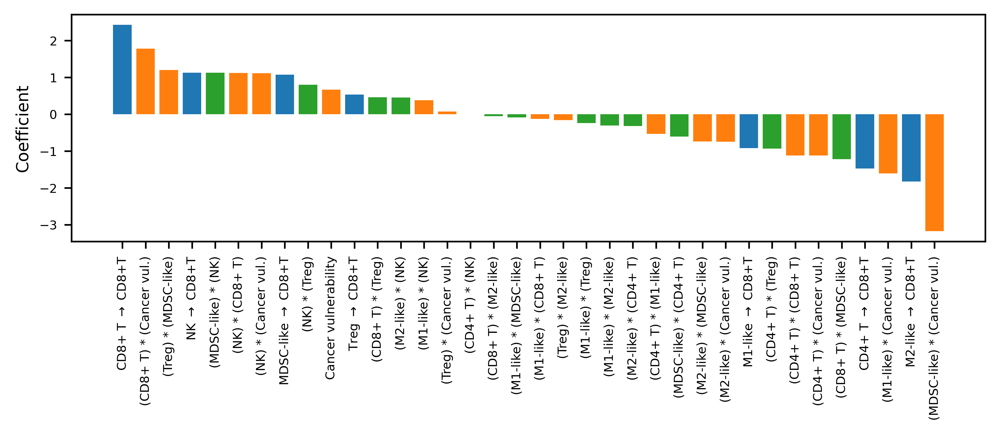

In [32]:
# Now we do all possible interactions
score_until = 2
score_df = merged_df_notx[merged_df_notx["hour"] < score_until].pivot_table(index=["set", "met"], aggfunc="sum")
score_df = pd.DataFrame(score_df.to_records()).drop(columns=["hour", "set", "CD8:cancer", "met", "infiltration"])
X_3 = score_df.values
X_3 = MinMaxScaler().fit_transform(X_3)
y = np.array(25 * [0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0]) # This is the classification of each  w/ 6 and 14 removed

# Do logistic regression
nonlinear_logistic = make_pipeline(
    PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
    MinMaxScaler(),
    LogisticRegression(solver='liblinear', max_iter=2500)               
    )
nonlinear_logistic.fit(X_3, y)
predictions = nonlinear_logistic.predict(X_3)
print("Accuracy: ", accuracy_score(y, predictions))
print("Balanced accuracy: ", balanced_accuracy_score(y, predictions))

# Extract features
regression = nonlinear_logistic.named_steps[nonlinear_logistic.steps[-1][0]]
poly = nonlinear_logistic.named_steps[nonlinear_logistic.steps[0][0]]
feature_importances = regression.coef_
num_features = len(feature_importances.reshape(-1))
names = poly.get_feature_names_out(input_features = score_df.columns)
waterfall_order = np.argsort(feature_importances.reshape(-1))[::-1]

# Rename the features
real_names = []
for name in names:
    if name in label_to_name.keys():
        real_names.append(label_to_name[name])
    else:
        parts = name.split(' ')
        pot_name_1 = "(" + label_to_abb[parts[0]] + ") * (" + label_to_abb[parts[1]] + ")"
        pot_name_2 = "(" + label_to_abb[parts[1]] + ") * (" + label_to_abb[parts[0]] + ")"
        if pot_name_2 in select_names:
            real_names.append(pot_name_2)
        else:
            real_names.append(pot_name_1)

# Get feature colors
select_names.append("Cancer vulnerability")
colors = ["tab:blue" if item in list(label_to_name.values())[:-1] else 
              ("tab:orange" if item in select_names else "tab:green") for item in real_names]


# Plot
fig, ax = plt.subplots(1, 1, figsize=(8, 2), dpi=600)
ax.bar(range(num_features), height = np.sort(feature_importances.reshape(-1))[::-1], color=np.array(colors)[waterfall_order])
ax.set(ylabel="Coefficient")
ax.set_xticks(range(num_features), np.array(real_names)[waterfall_order], rotation=90);

The following cell generates **Sup. Fig. 5C**, which plots the ROC curves for all three logistic regressions.

/home1/kingtyle/.local/lib/python3.13/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home1/kingtyle/.local/lib/python3.13/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
/home1/kingtyle/.local/lib/python3.13/site-packages/sklearn/utils/_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


<bound method Axes.legend of <Axes: title={'center': 'ROC curves'}, xlabel='FPR', ylabel='TPR'>>

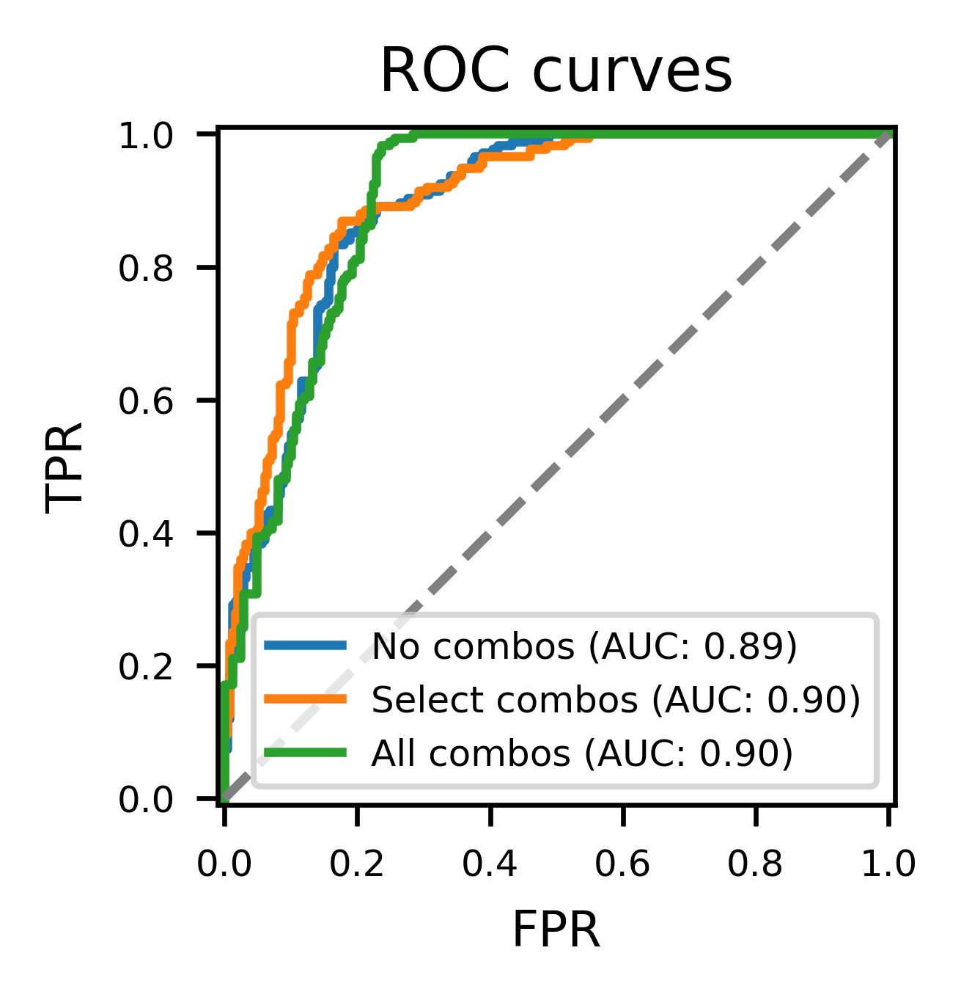

In [33]:
fig, ax = plt.subplots(1, 1, figsize=(2, 2), dpi=600)
RocCurveDisplay.from_estimator(clf_1, X_1, y, ax=ax, label=f"No combos (AUC: {roc_auc_score(y, clf_1.predict_proba(X_1)[:,1]):.2f})")
RocCurveDisplay.from_estimator(clf_2, X_2, y, ax=ax, label=f"Select combos (AUC: {roc_auc_score(y, clf_2.predict_proba(X_2)[:,1]):.2f})")
RocCurveDisplay.from_estimator(nonlinear_logistic, X_3, y, ax=ax, label=f"All combos (AUC: {roc_auc_score(y, nonlinear_logistic.predict_proba(X_3)[:,1]):.2f})")
ax.plot([0, 1], [0, 1], c="tab:gray", ls="--")
ax.set(xlabel="FPR", ylabel="TPR", title="ROC curves")
ax.legend

## Figure 6 -- Analysis of multicellular structures across metastases via local neighborhood analysis of early simulation timecourses.

This also generates: **Sup Fig. S6**, which provides a more detailed view of the clustering dendrograms in Fig. 6; **Sup. Fig. S7**, which shows the definitions for each of the thirty neighborhood clusters; and **Figure 8**, which shows the spatial organization of a metastasis that is responsive to Treg depletion but not MDSC depletion.

In [34]:
# If you have already generated the data, load it, then convert string type neighbors column back into a numpy array
path_to_data = f"{path_to_precomputed}/allmets_first2days_k10.feather"
full_data_df = pd.read_feather(path_to_data)

In [35]:
n_clusters = 30
seed = 0 # This MUST be specified as seed = 0 in order for the results to match what is presented in the paper
batch_size = 1 + 256*64 # batch size should be set to 1 + 256*64 to properly replicate the clustering results; this is good performance-wise if cpu_cores <= 64

# Run MiniBatchKMeans to identify neighborhoods 
kmeans = MiniBatchKMeans(n_clusters = n_clusters, random_state=seed, batch_size=batch_size)
X = np.stack(full_data_df["neighbors"].values)
labels = kmeans.fit_predict(X)
centroids = {}
centroids = kmeans.cluster_centers_
full_data_df["neighborhood"] = labels

The below two cells generate **Sup. Fig. 6A** and **B**, which provide ways to identify clusters based on the location of the centroid (either relative to the other clusters via Z-score or via absolute position).

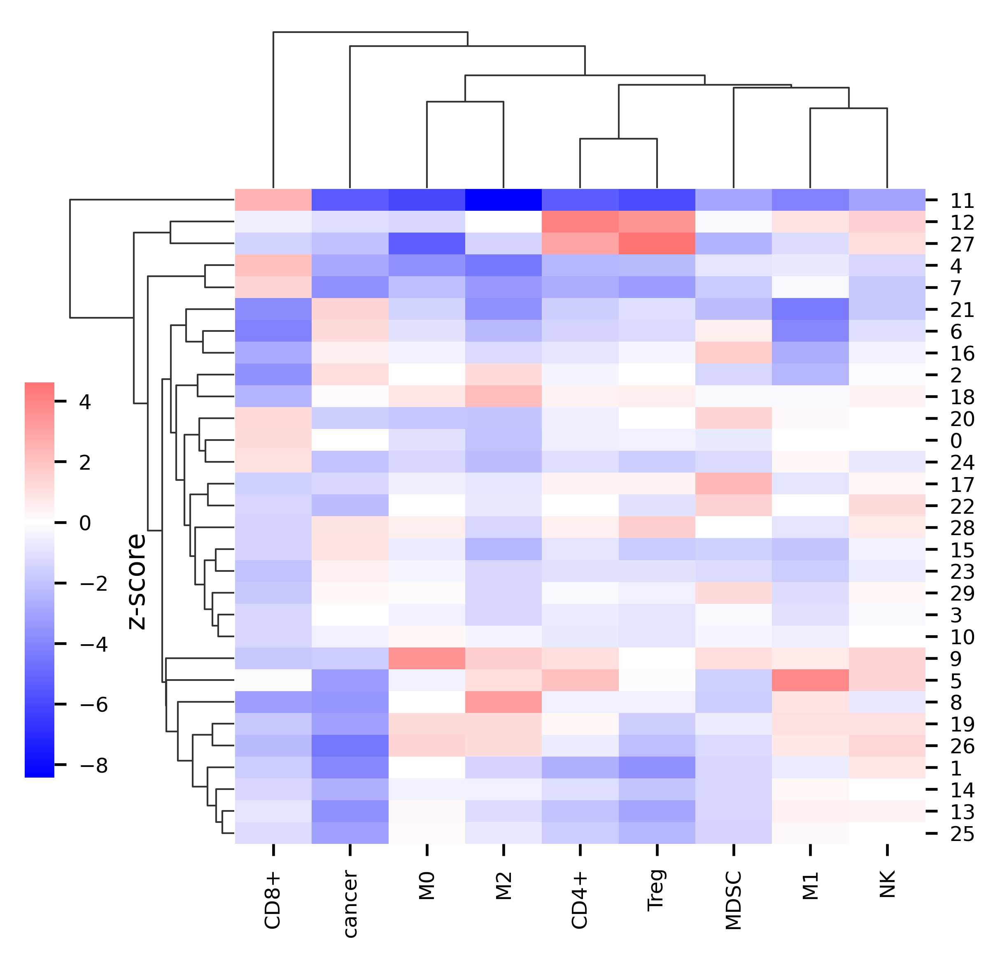

In [36]:
# Calculate log2(fold-change) from average value for each cluster centroid and plot
average_value = X.mean(axis=0)
foldchange = pd.DataFrame(np.log2(centroids / average_value), columns = list(dict_cell_colors.keys()))
foldchange_nogeneral = foldchange.drop(columns=["myeloid", "lymphoid", "stromal"]) # Drop non-functional generalized cells
cg = sns.clustermap(foldchange_nogeneral, cmap='bwr', yticklabels=True, center=0, figsize=(4, 4), cbar_pos=(0, .2, .03, .4), cbar_kws={'label':'z-score'})
cg.fig.set_dpi(600)

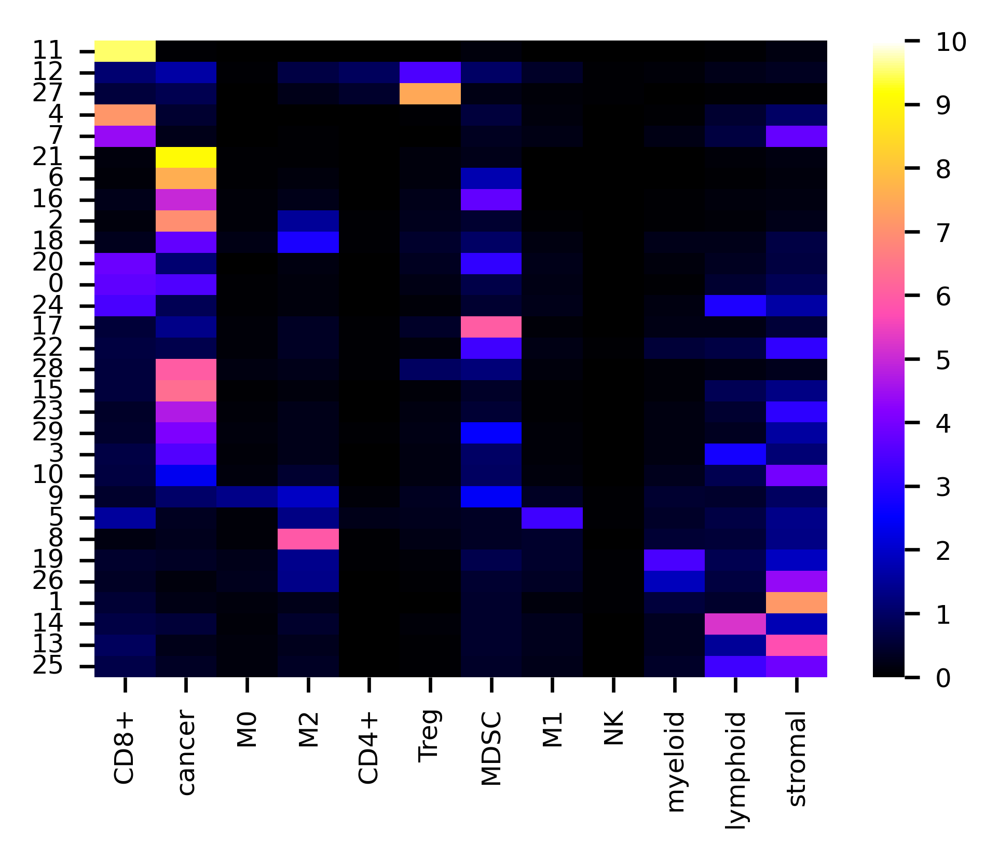

In [37]:
# Calculate the positions of each centroid, which gives an approximation of the neighborhood's absolute composition
centroid_df = pd.DataFrame(centroids, columns=list(dict_cell_colors.keys()))
centroids_nogeneral = centroid_df.drop(columns=["myeloid", "lymphoid", "stromal"])

rows = cg.dendrogram_row.reordered_ind
cols = cg.dendrogram_col.reordered_ind

bbox = cg.ax_heatmap.get_window_extent().transformed(cg.fig.dpi_scale_trans.inverted())
fig, ax = plt.subplots(figsize=(bbox.width + 1, bbox.height), dpi=600)

reord_centroids = centroids_nogeneral.iloc[rows, cols]
reord_centroids = pd.concat([reord_centroids, centroid_df.iloc[rows][["myeloid", "lymphoid", "stromal"]]], axis=1)
sns.heatmap(reord_centroids, ax=ax, cmap="gnuplot2", vmin=0, vmax=10, yticklabels=True)

cbar = ax.collections[0].colorbar
cbar.ax.locator_params(nbins=10)

In [38]:
# These are manually-specified names for each neighborhood, and some neighborhoods have a more specific secondary name
# For each neighborhood, the dict maps a key (neighborhood #) to the value [main name, secondary modifier]
# If there is no secondary modifier, the second value in the list is an empty string

neighborhood_names = {
    0: ['CD8+ infiltrated tumor',   ''],
    1: ['generalized cell zone',    ''],
    2: ['myeloid suppressed tumor', 'M2-enriched'],
    3: ['tumor', ''],
    4: ['CD8+ T cell region',       ''],
    5: ['T cell activation region', ''],
    6: ['tumor', ''],
    7: ['CD8+ T cell region',       ''],
    8: ['M2 region',                 ''],
    9: ['myeloid suppressed tumor', 'M2/MDSC-enriched'],
    10:['myeloid suppressed tumor', 'MDSC-enriched'],
    11:['CD8+ T cell region',       ''],
    12:['CD8+ infiltrated tumor',   'suppressed'],
    13:['generalized cell zone',    ''],
    14:['generalized cell zone',    ''],
    15:['tumor',                    ''],
    16:['myeloid suppressed tumor', 'MDSC-enriched'],
    17:['MDSC region',              ''],
    18:['myeloid suppressed tumor', 'M2/MDSC-enriched'],
    19:['myeloid region',           ''],
    20:['CD8+ infiltrated tumor',   'suppressed'],
    21:['tumor',                    ''],
    22:['MDSC region',              ''],
    23:['tumor',                    ''],
    24:['CD8+ T cell region',       ''],
    25:['generalized cell zone',    ''],
    26:['myeloid region',           ''],
    27:['suppressed tumor',         'Treg-enriched'],
    28:['suppressed tumor',         'MDSC/Treg-enriched'],
    29:['myeloid suppressed tumor', 'MDSC-enriched'],
}

full_data_df["l1_name"] = full_data_df["neighborhood"].apply(lambda x: neighborhood_names[x][0])
full_data_df["l2_name"] = full_data_df["neighborhood"].apply(lambda x: " ".join(filter(None, [neighborhood_names[x][1], neighborhood_names[x][0]])))

full_data_df["l1_name"] = full_data_df["l1_name"].astype('category')
full_data_df["l2_name"] = full_data_df["l2_name"].astype('category')

The below cell generates **Figure 6C**, which shows the neighborhood compositions of metastases over the first 48 hours of simulation. Additionally, we cluster these mets based on neighborhood composition.

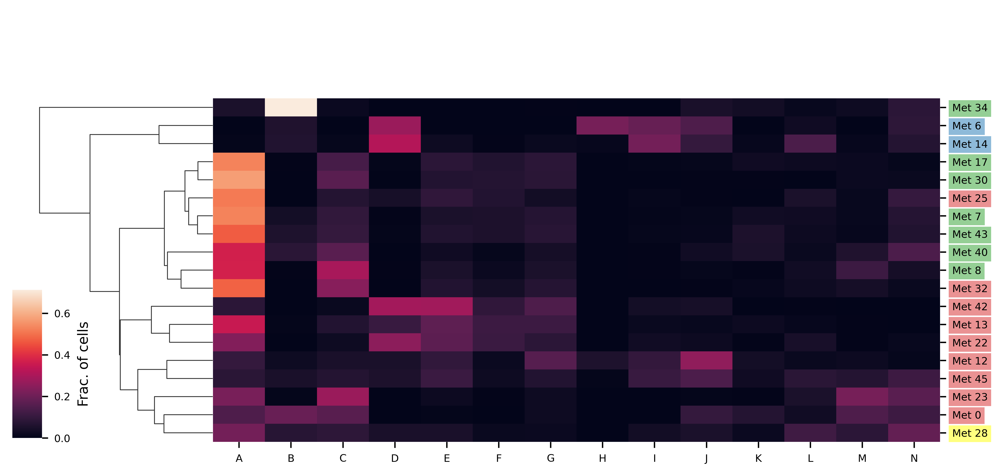

In [39]:
l2_to_alpha = {'tumor': 'A',
 'CD8+ T cell region': 'B',
 'MDSC-enriched myeloid suppressed tumor': 'C',
 'M2 region': 'D',
 'M2/MDSC-enriched myeloid suppressed tumor': 'E',
 'M2-enriched myeloid suppressed tumor': 'F',
 'MDSC/Treg-enriched suppressed tumor': 'G',
 'Treg-enriched suppressed tumor': 'H',
 'T cell activation region': 'I',
 'suppressed CD8+ infiltrated tumor': 'J',
 'CD8+ infiltrated tumor': 'K',
 'myeloid region': 'L',
 'MDSC region': 'M',
 'generalized cell zone': 'N'}

met_order = [0, 6, 7, 8, 12, 13, 14, 17, 22, 23, 25, 28, 30, 32, 34, 40, 42, 43, 45]
neigh_metcounts = pd.crosstab(full_data_df["l2_name"], full_data_df["met"])
neigh_metcounts = neigh_metcounts.T
neigh_ratios = neigh_metcounts.div(neigh_metcounts.sum(axis=1), axis=0)

cg = sns.clustermap(neigh_ratios[l2_to_alpha.keys()], col_cluster=False, yticklabels=True, figsize=(8, 6), cbar_pos=(0, 0.40, .03, .2), cbar_kws={'label':'Frac. of cells'})
cg.fig.set_dpi(600)

# The neighborhood names are quite long, so we will substitute with ALPHA codes
xticks = cg.fig.get_axes()[2].get_xticklabels()
l2_names = [elem.get_text() for elem in xticks]
yticks = cg.fig.get_axes()[2].get_yticklabels()
alphalist = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N']
cg.fig.get_axes()[2].set_xticklabels(alphalist, rotation=0)
cg.fig.get_axes()[2].set_yticklabels(["Met " + str(int(met.get_text())-100) for met in yticks], rotation=0) # Use the non-100 series numbering system
cg.fig.get_axes()[2].set(xlabel="", ylabel="")

# Based on the order of the ticks, the mets are sorted into the following categories
# 0 = TX effect, 1 = no TX effect & PD, 2 = bifurcations, 3 = no TX effect & SD
classes_to_color = {0:'tab:green', 1:'tab:red', 2:'tab:blue', 3:'yellow'}
classes = [0, 2, 2, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 3]
labels = cg.fig.get_axes()[2].get_yticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

The following cell generates **Sup. Fig. S6A**, which shows the clustering from the above heatmap in greater detail.

[[ 7.         12.          0.08525322  2.        ]
 [ 2.         17.          0.08715293  2.        ]
 [10.         20.          0.13874193  3.        ]
 [19.         21.          0.15983216  5.        ]
 [ 3.         13.          0.18299012  2.        ]
 [ 5.          8.          0.24929526  2.        ]
 [15.         23.          0.26083421  3.        ]
 [ 4.         18.          0.26469745  2.        ]
 [22.         25.          0.27894432  8.        ]
 [ 0.         11.          0.28126202  2.        ]
 [ 1.          6.          0.30942321  2.        ]
 [ 9.         28.          0.33596737  3.        ]
 [16.         24.          0.35455327  3.        ]
 [26.         30.          0.43272005  5.        ]
 [31.         32.          0.53308647  8.        ]
 [27.         33.          0.53791706 16.        ]
 [29.         34.          0.70798069 18.        ]
 [14.         35.          1.         19.        ]]


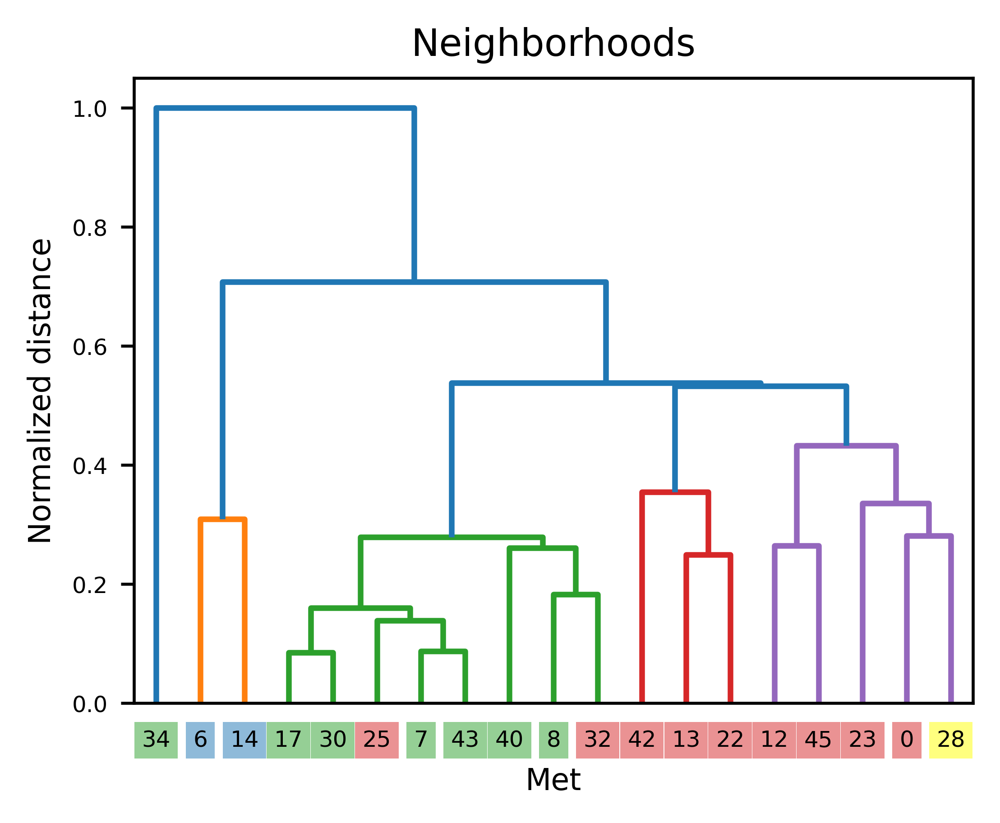

In [40]:
fig, ax = plt.subplots(figsize=(4, 3), dpi=600)
row_linkage_mat = cg.dendrogram_row.linkage # Get linkage matrix
row_linkage_mat[:,2] = row_linkage_mat[:,2] / max(row_linkage_mat[:,2]) # Normalize so last merge is at 1
print(row_linkage_mat)

dendrogram(row_linkage_mat, labels=met_order, color_threshold=0.5, ax=ax, leaf_font_size=6);
ax.set(xlabel="Met", ylabel="Normalized distance", title="Neighborhoods")
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

The below cell generates **Figure 6D**, which shows the cell type compositions of metastases over the first 48 hours of simulation. Additionally, we cluster these mets based on cell type composition.

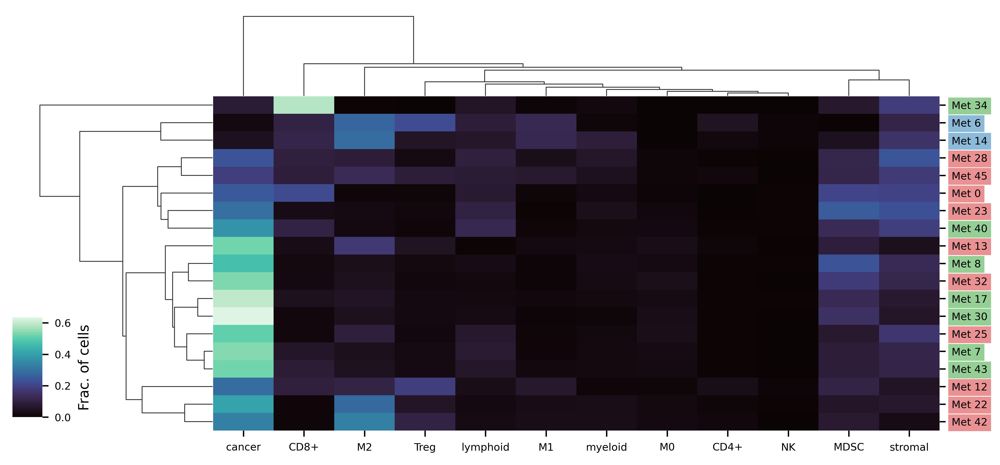

In [41]:
cell_metcounts = pd.crosstab(full_data_df["ctype"], full_data_df["met"])
cell_metcounts = cell_metcounts.T
cell_ratios = cell_metcounts.div(cell_metcounts.sum(axis=1), axis=0)

cg = sns.clustermap(cell_ratios, cmap="mako", yticklabels=True, figsize=(8, 4), cbar_pos=(0, 0.15, .03, .2), cbar_kws={'label':'Frac. of cells'})
cg.fig.set_dpi(600)

# The neighborhood names are quite long, so we will substitute with ALPHA codes
xticks = cg.fig.get_axes()[2].get_xticklabels()
yticks = cg.fig.get_axes()[2].get_yticklabels()
cg.fig.get_axes()[2].set_yticklabels(["Met " + str(int(met.get_text())-100) for met in yticks], rotation=0) # Use the non-100 series numbering system
cg.fig.get_axes()[2].set(xlabel="", ylabel="")

# Based on the order of the ticks, the mets are sorted into the following categories
# 0 = TX effect, 1 = no TX effect & PD, 2 = bifurcations, 3 = no TX effect & SD
classes = [0, 2, 2, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1]
labels = cg.fig.get_axes()[2].get_yticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

The following cell generates **Sup. Fig. S6B**, which shows the clustering from the above heatmap in greater detail.

[[ 2.         17.          0.04996908  2.        ]
 [ 7.         12.          0.08710195  2.        ]
 [ 3.         13.          0.14127894  2.        ]
 [10.         19.          0.15007558  3.        ]
 [ 8.         16.          0.16300761  2.        ]
 [11.         18.          0.18163082  2.        ]
 [20.         22.          0.22159806  5.        ]
 [21.         25.          0.23187114  7.        ]
 [ 9.         15.          0.25887676  2.        ]
 [ 5.         26.          0.27376924  8.        ]
 [ 0.         27.          0.2993889   3.        ]
 [ 1.          6.          0.30058857  2.        ]
 [24.         29.          0.31826724  5.        ]
 [ 4.         23.          0.40820365  3.        ]
 [28.         32.          0.50161232 11.        ]
 [31.         33.          0.52056335 16.        ]
 [30.         34.          0.76868144 18.        ]
 [14.         35.          1.         19.        ]]


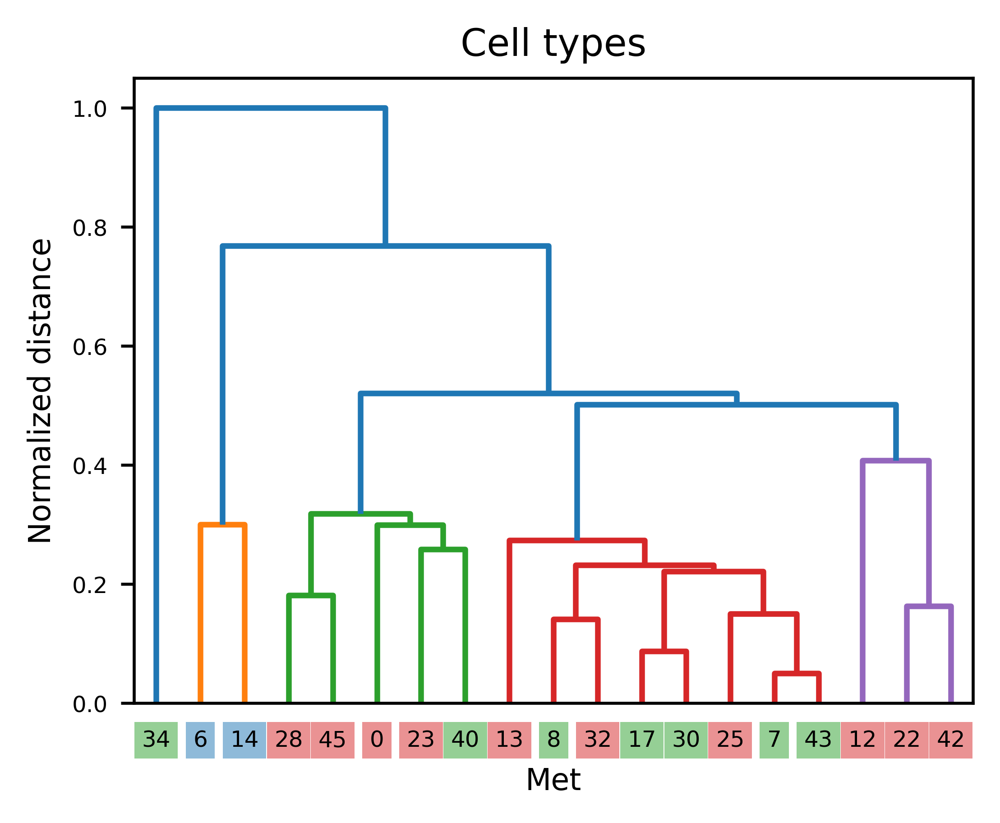

In [42]:
fig, ax = plt.subplots(figsize=(4, 3), dpi=600)
row_linkage_mat = cg.dendrogram_row.linkage # Get linkage matrix
row_linkage_mat[:,2] = row_linkage_mat[:,2] / max(row_linkage_mat[:,2]) # Normalize so last merge is at 1
print(row_linkage_mat)

dendrogram(row_linkage_mat, labels=met_order, color_threshold=0.5, ax=ax, leaf_font_size=6);
ax.set(xlabel="Met", ylabel="Normalized distance", title="Cell types")
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

The following cell generates **Sup. Fig. 6C**, which shows the cell type composition of each neighborhood cluster.

[Text(0.5, 1.0, '')]

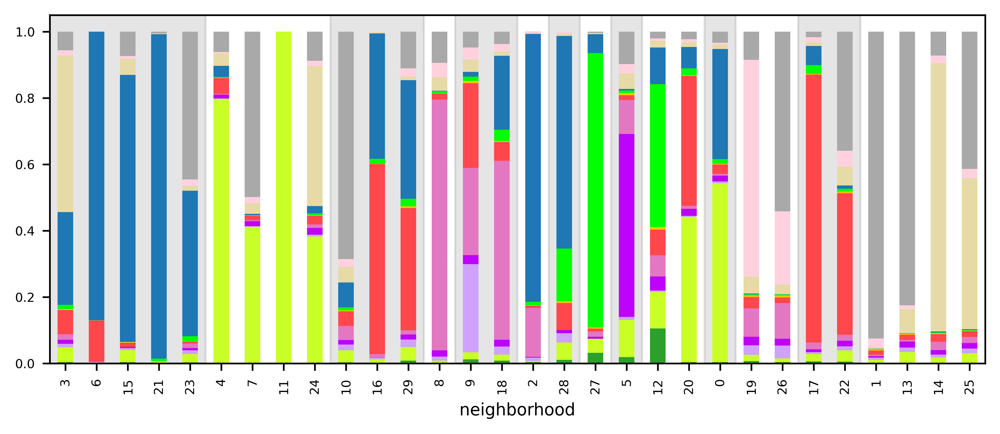

In [43]:
neigh_to_num = {}
index_order = []

for cat in l2_to_alpha.keys():
    members = []
    for i in range(30):
        name = " ".join(filter(None, [neighborhood_names[i][1], neighborhood_names[i][0]]))
        if name == cat:
            members.append(i)
            index_order.append(i)
    neigh_to_num[cat] = members

spans = []
for key in neigh_to_num.keys():
    spans.append(len(neigh_to_num[key]))

# Calculate the cell type composition of each neighborhood
neigh_cellcounts = pd.crosstab(full_data_df["neighborhood"], full_data_df["ctype"])
neigh_cellratios = neigh_cellcounts.div(neigh_cellcounts.sum(axis=1), axis=0)
neigh_cellratios = neigh_cellratios.iloc[index_order]
fig, ax = plt.subplots(figsize=(8, 3), dpi=600)

# Plot the neighborhood groupings first
start = -0.5
display = True
for span in spans:
    if display:
        ax.axvspan(start, start + span, alpha = 0.1, color="k")
        start = start + span
        display = False
    else:
        display = True
        start = start + span

# Then do the bar plot
neigh_cellratios.plot.bar(stacked=True, color=dict_cell_colors, legend=False, ax=ax)
ax.set(title="")

The below cells generate the subpanels of **Figure 6A**.

/tmp/SLURM_6780182/ipykernel_3468985/3452606453.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_to_plot['l2_name'] = df_to_plot['l2_name'].astype(cat_type)
/tmp/SLURM_6780182/ipykernel_3468985/3452606453.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_to_plot["state"] = df_to_plot["state"].map(adjust_state)
/tmp/SLURM_6780182/ipykernel_3468985/3452606453.py:48: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Spe

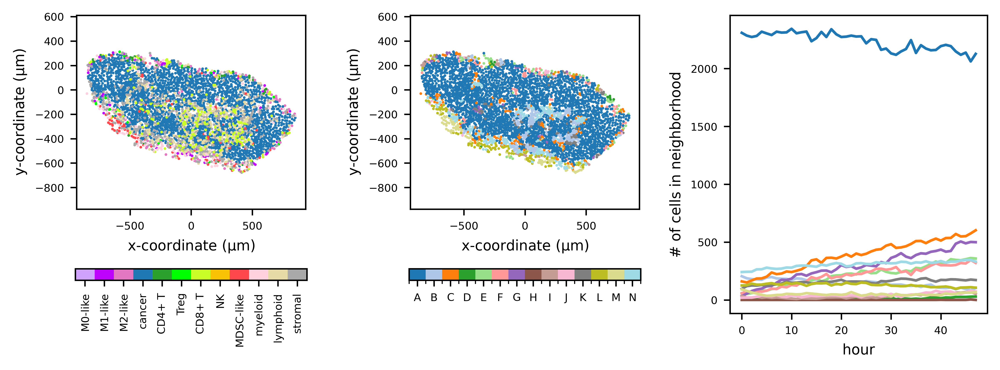

In [44]:
# Get a single frame of a met
met = 107
hour = 0

df_to_plot = full_data_df[
    (full_data_df["met"] == met) *
    (full_data_df["hour"] == hour) *
    (full_data_df["rep"] == 0)]

# Convert the neighborhood labels to an ordered categorical
cat_type = pd.CategoricalDtype(categories=l2_names, ordered=True)
df_to_plot['l2_name'] = df_to_plot['l2_name'].astype(cat_type)

# Fix the state labels for plotting w/ cmap
df_to_plot["state"] = df_to_plot["state"].map(adjust_state)

fig, ax = plt.subplots(1, 3, figsize=(8, 3), dpi=600)

# Plot the first scatter to read_in the extents of the plot, then remove it
df_to_plot.plot.scatter('x', 'y', c="state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, ax=ax[0], s=1, colorbar=False)
scale = (6.4 / (max(ax[0].get_xlim()[1] - ax[0].get_xlim()[0], ax[0].get_ylim()[1] - ax[0].get_ylim()[0]) * 2 + 1) * 300.) ** 2
ax[0].clear()

# Plot the two scatterplots
y_pad = 250
s1 = df_to_plot.plot.scatter('x', 'y', c="state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, ax=ax[0], s=scale, colorbar=False)
s2 = df_to_plot.plot.scatter('x', 'y', c="l2_name", ax=ax[1], s=scale, colorbar=False, colormap='tab20')
ax[0].set(xlabel=r"x-coordinate ($\mathrm{\mu}$m)", ylabel=r"y-coordinate ($\mathrm{\mu}$m)", 
          ylim=(ax[0].get_ylim()[0] - y_pad, ax[0].get_ylim()[1] + y_pad))
ax[0].set_aspect(1)
ax[1].set(xlabel=r"x-coordinate ($\mathrm{\mu}$m)", ylabel=r"y-coordinate ($\mathrm{\mu}$m)", 
          ylim=(ax[1].get_ylim()[0] - y_pad, ax[1].get_ylim()[1] + y_pad))
ax[1].set_aspect(1)

# Plot their colorbars
cbar1 = fig.colorbar(s1.collections[0], orientation='horizontal', location='bottom', shrink=0.9, pad=.2)
cbar1.set_ticks(np.arange(0, 12, 1))
cbar1.set_ticklabels(["M0-like", "M1-like", "M2-like", "cancer", "CD4+ T", "Treg", "CD8+ T", "NK", "MDSC-like", "myeloid", "lymphoid", "stromal"], rotation=90)
    
cbar2 = fig.colorbar(s2.collections[0], orientation='horizontal', location='bottom', shrink=0.9, pad=.2)
cbar2.set_ticks(np.arange(0.5, 14.5, 1))
cbar2.set_ticklabels(alphalist)
    
# Now we get the neighborhood composition of the first 48 hours of simulation
df_to_plot = full_data_df[
    (full_data_df["met"] == met) *
    (full_data_df["rep"] == 0)]
pt = pd.pivot_table(df_to_plot, values='x', columns="l2_name", index="hour", aggfunc='count')
pt = pt[l2_names]

from matplotlib.colors import ListedColormap
colors = np.array(plt.get_cmap('tab20').colors)
colors = colors[[0, 1, 2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17, 19]]
pt[l2_names].plot(legend=False, ax=ax[2], cmap=ListedColormap(colors))

ax[2].set(ylabel="# of cells in neighborhood")

fig.tight_layout()

The below generate parts of **Figure 8**.

/tmp/SLURM_6780182/ipykernel_3468985/1111362748.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_to_plot['l2_name'] = df_to_plot['l2_name'].astype(cat_type)
/tmp/SLURM_6780182/ipykernel_3468985/1111362748.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_to_plot["state"] = df_to_plot["state"].map(adjust_state)


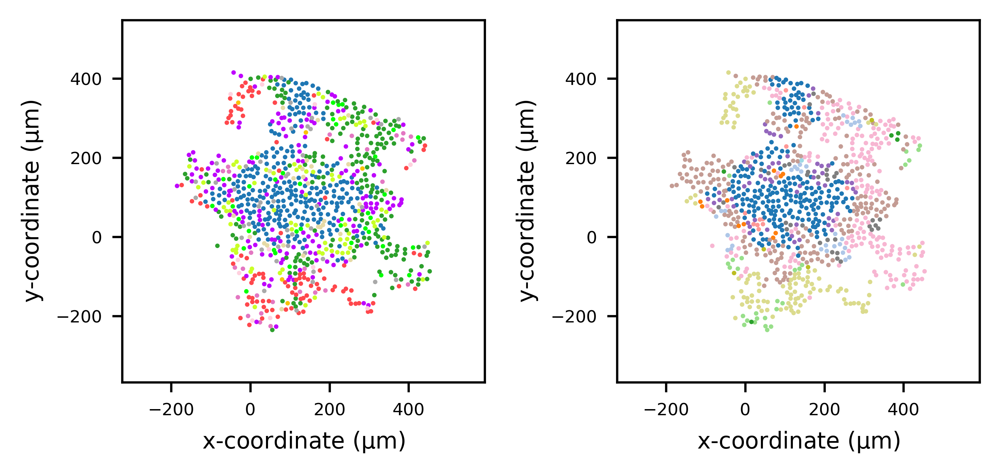

In [45]:
# Get a single frame of a met
df_to_plot = full_data_df[(full_data_df["met"] == 112) * (full_data_df["hour"] == 0) * (full_data_df["rep"] == 0)]
alphalist = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N']

# Convert the neighborhood labels to an ordered categorical
cat_type = pd.CategoricalDtype(categories=l2_names, ordered=True)
df_to_plot['l2_name'] = df_to_plot['l2_name'].astype(cat_type)

# Fix the state labels for plotting w/ cmap
df_to_plot["state"] = df_to_plot["state"].map(adjust_state)

fig, ax = plt.subplots(1, 2, figsize=(5, 3), dpi=600)

# Plot the first scatter to read_in the extents of the plot, then remove it
df_to_plot.plot.scatter('x', 'y', c="state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, ax=ax[0], s=1, colorbar=False)
scale = (6.4 / (max(ax[0].get_xlim()[1] - ax[0].get_xlim()[0], ax[0].get_ylim()[1] - ax[0].get_ylim()[0]) * 2 + 1) * 300.) ** 2
width = max(ax[0].get_xlim()[1] - ax[0].get_xlim()[0], ax[0].get_ylim()[1] - ax[0].get_ylim()[0])
ax[0].clear()

# Plot the two scatterplots
pad = 100
s1 = df_to_plot.plot.scatter('x', 'y', c="state", colormap=cell_cmap, vmin=-0.5, vmax=11.5, ax=ax[0], s=scale, colorbar=False, linewidths=0.25)
s2 = df_to_plot.plot.scatter('x', 'y', c="l2_name", ax=ax[1], s=scale, colorbar=False, colormap=ListedColormap(colors),linewidths=0.25)
ax[0].set(xlabel=r"x-coordinate ($\mathrm{\mu}$m)", ylabel=r"y-coordinate ($\mathrm{\mu}$m)", 
          ylim=(sum(ax[0].get_ylim())/2 - width/2 - pad, sum(ax[0].get_ylim())/2 + width/2 + pad),
          xlim=(sum(ax[0].get_xlim())/2 - width/2 - pad, sum(ax[0].get_xlim())/2 + width/2 + pad))
ax[1].set(xlabel=r"x-coordinate ($\mathrm{\mu}$m)", ylabel=r"y-coordinate ($\mathrm{\mu}$m)", 
          ylim=(sum(ax[0].get_ylim())/2 - width/2 - pad, sum(ax[0].get_ylim())/2 + width/2 + pad),
          xlim=(sum(ax[0].get_xlim())/2 - width/2 - pad, sum(ax[0].get_xlim())/2 + width/2 + pad))
ax[0].set_aspect(1)
ax[1].set_aspect(1)
fig.tight_layout()

## Figure 7 -- Modeling blockade of specific cell types

The below creates **Figure 7A**, which is the cancer growth w/ MDSC blockade.

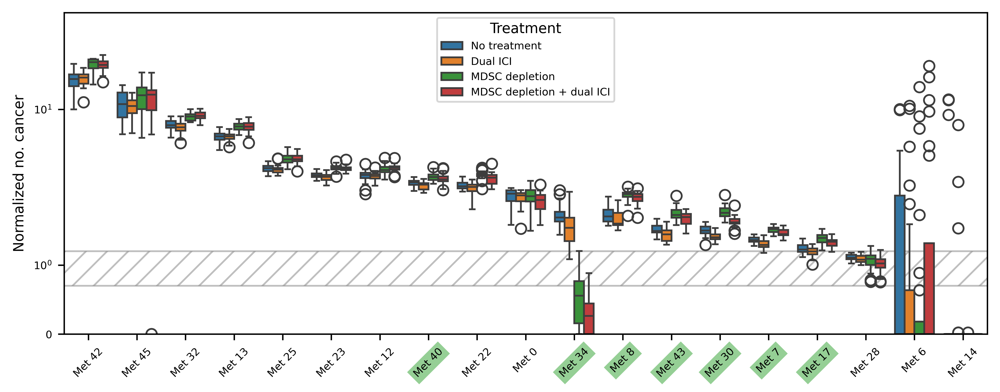

In [46]:
# Collect data
num_replicates = 25
mets = [0, 6, 7, 8, 12, 13, 14, 17, 22, 23, 25, 28, 30, 32, 34, 40, 42, 43, 45]
all_results = []
for met in mets:
    for j in range(num_replicates):
        orig = os.path.join(path_to_simulations, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        orig_tx = os.path.join(path_to_simulations, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        path = os.path.join(path_to_mdsc_dep, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        tx_path = os.path.join(path_to_mdsc_dep, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        orig_data = pd.read_csv(orig, header=0)
        orig_tx_data = pd.read_csv(orig_tx, header=0)
        data = pd.read_csv(path, header=0)
        tx_data = pd.read_csv(tx_path, header=0)
        all_results.append([orig_data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "No treatment"])
        all_results.append([orig_tx_data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "Dual ICI"])
        all_results.append([data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "MDSC depletion"])
        all_results.append([tx_data["c"].tolist()[-1], tx_data["c"].tolist()[0], f"Met {met}", "MDSC depletion + dual ICI"])

all_results = pd.DataFrame(all_results, columns=["Final cancer", "Initial cancer", "Met", "Treatment"])
all_results["Normalized no. cancer"] = all_results["Final cancer"].astype(float) / all_results["Initial cancer"].astype(float)
all_results["Normalized sqrt(no. cancer)"] = np.sqrt(all_results["Final cancer"].astype(float)) / np.sqrt(all_results["Initial cancer"].astype(float))

# Set tab10 colormap as the default
colors = plt.get_cmap('tab10').colors
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

# Set order of metastases based on endpoint size
all_results['Met'] = all_results['Met'].astype('category')
all_results['Met'] = all_results['Met'].cat.reorder_categories(
    ['Met 42', 'Met 45', 'Met 32', 'Met 13', 'Met 25', 'Met 23', 'Met 12', 'Met 40', 'Met 22', 'Met 0', 'Met 34', 
     'Met 8', 'Met 43', 'Met 30', 'Met 7', 'Met 17', 'Met 28', 'Met 6', 'Met 14'])

# Plot the data
fig, ax = plt.subplots(1, 1, figsize=(8, 3.2), dpi=600)
ax.fill_between(np.arange(-1, 20), 0.7, 1.2, color='grey', alpha=0.5, hatch="//", facecolor='none')
sns.boxplot(data=all_results, x="Met", y="Normalized no. cancer", hue="Treatment", ax=ax)
ax.set(yscale='symlog', ylim=(0, 60), title="", xlabel="", ylabel="Normalized no. cancer")
ax.tick_params(axis='x', rotation=45)

classes = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0]
classes_to_color = {0:'none', 1:'tab:green'}
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

fig.tight_layout()

In [47]:
table = pd.pivot_table(all_results, values=["Normalized no. cancer"], index=["Met", "Treatment"], aggfunc="mean")
table = table.reset_index(level=1)
wide = table.pivot(columns="Treatment", values="Normalized no. cancer")
wide = wide[["No treatment", "Dual ICI", "MDSC depletion", "MDSC depletion + dual ICI"]]
wide["ICI prop"] = -100*((wide["No treatment"] - wide["Dual ICI"]) / wide["No treatment"])
wide["MDSC depletion prop"] = -100*((wide["No treatment"] - wide["MDSC depletion"]) / wide["No treatment"])
wide["MDSC depletion + ICI prop"] = -100*((wide["No treatment"] - wide["MDSC depletion + dual ICI"]) / wide["No treatment"])
wide

/tmp/SLURM_6780182/ipykernel_3468985/2643073702.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table = pd.pivot_table(all_results, values=["Normalized no. cancer"], index=["Met", "Treatment"], aggfunc="mean")


Treatment,No treatment,Dual ICI,MDSC depletion,MDSC depletion + dual ICI,ICI prop,MDSC depletion prop,MDSC depletion + ICI prop
Met,,,,,,,
Met 42,17.407742,17.692903,23.101935,22.705806,1.638129,32.710696,30.435105
Met 45,10.962034,10.501695,12.831864,12.172881,-4.199394,17.057332,11.045828
Met 32,7.497944,7.154019,8.689720,8.859813,-4.586927,15.894700,18.163235
Met 13,6.034516,6.031613,7.288710,7.226452,-0.048110,20.783664,19.751965
Met 25,3.339033,3.294572,3.980669,3.949442,-1.331552,19.216210,18.281006
Met 23,2.949346,2.848411,3.361589,3.352056,-3.422270,13.977438,13.654224
Met 12,2.913043,2.882846,3.309091,3.359842,-1.036635,13.595658,15.337856
Met 40,2.551756,2.435691,2.878782,2.760000,-4.548458,12.815712,8.160793
Met 22,2.451111,2.343232,2.964545,2.780303,-4.401220,20.947004,13.430314


In [48]:
stat_results = []
for met in wide.index:
    notx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "No treatment")]["Normalized no. cancer"]
    tx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "Dual ICI")]["Normalized no. cancer"]
    dep_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "MDSC depletion")]["Normalized no. cancer"]
    dep_tx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "MDSC depletion + dual ICI")]["Normalized no. cancer"]
    if (met == "Met 14") or (met == "Met 6"):
        results = [mannwhitneyu(notx_vals, dep_vals),
                   mannwhitneyu(notx_vals, dep_tx_vals),
                   mannwhitneyu(tx_vals, dep_vals),
                   mannwhitneyu(tx_vals, dep_tx_vals)]
    else:
        results = [ttest_ind(notx_vals, dep_vals),
                   ttest_ind(notx_vals, dep_tx_vals),
                   ttest_ind(tx_vals, dep_vals),
                   ttest_ind(tx_vals, dep_tx_vals)]
    p_vals = np.array(results)[:,1]
    stat_results.append(p_vals)
stat_results = np.array(stat_results)

# This slicing retreives the p-value
wide["notx vs. dep"] = stat_results[:,0]
wide["notx vs. dep + ICI"] = stat_results[:,1]
wide["ICI vs. dep"] = stat_results[:,2]
wide["ICI vs. dep + ICI"] = stat_results[:,3]

# We calculate the effect sizes for each comparison
wide["notx vs. dep eff"] = -100*((wide["No treatment"] - wide["MDSC depletion"]) / wide["No treatment"])
wide["notx vs. dep + ICI eff"] = -100*((wide["No treatment"] - wide["MDSC depletion + dual ICI"]) / wide["No treatment"])
wide["ICI vs. dep eff"] = -100*((wide["Dual ICI"] - wide["MDSC depletion"]) / wide["Dual ICI"])
wide["ICI vs. dep + ICI eff"] = -100*((wide["Dual ICI"] - wide["MDSC depletion + dual ICI"]) / wide["Dual ICI"])
effects = wide[["notx vs. dep eff", "notx vs. dep + ICI eff", "ICI vs. dep eff", "ICI vs. dep + ICI eff"]]

# Filter effects for significant p-values -- if the effect is zero it's because the p-value is >= 0.05
pvals = wide[["notx vs. dep", "notx vs. dep + ICI", "ICI vs. dep", "ICI vs. dep + ICI"]]
mdsc_pval_table = effects * (pvals < 0.05).to_numpy()

mdsc_pval_table

Treatment,notx vs. dep eff,notx vs. dep + ICI eff,ICI vs. dep eff,ICI vs. dep + ICI eff
Met,,,,
Met 42,32.710696,30.435105,30.571762,28.332847
Met 45,17.057332,0.000000,22.188509,0.000000
Met 32,15.894700,18.163235,21.466270,23.843863
Met 13,20.783664,19.751965,20.841801,19.809605
Met 25,19.216210,18.281006,20.825059,19.877234
Met 23,13.977438,13.654224,18.016274,17.681606
Met 12,13.595658,15.337856,14.785565,16.546013
Met 40,12.815712,8.160793,18.191608,13.314873
Met 22,20.947004,13.430314,26.515217,18.652470


In [49]:
conds = ["No treatment", "Dual ICI", "MDSC depletion", "MDSC depletion + dual ICI"]
for cond in conds:
    num_elim = sum(all_results[(all_results["Met"] == "Met 6") & (all_results["Treatment"] == cond)]["Normalized no. cancer"] == 0)
    print(f"For {cond}, {100*num_elim/25:.2f}% ({num_elim}) replicates are CR in MET 6.")
print('\n')
for cond in conds:
    num_elim = sum(all_results[(all_results["Met"] == "Met 14") & (all_results["Treatment"] == cond)]["Normalized no. cancer"] == 0)
    print(f"For {cond}, {100*num_elim/25:.2f}% ({num_elim}) replicates are CR in MET 14.")

For No treatment, 60.00% (15) replicates are CR in MET 6.
For Dual ICI, 56.00% (14) replicates are CR in MET 6.
For MDSC depletion, 60.00% (15) replicates are CR in MET 6.
For MDSC depletion + dual ICI, 56.00% (14) replicates are CR in MET 6.


For No treatment, 88.00% (22) replicates are CR in MET 14.
For Dual ICI, 80.00% (20) replicates are CR in MET 14.
For MDSC depletion, 96.00% (24) replicates are CR in MET 14.
For MDSC depletion + dual ICI, 100.00% (25) replicates are CR in MET 14.


The below creates **Figure 7C**, which is the cancer growth w/ Treg blockade.

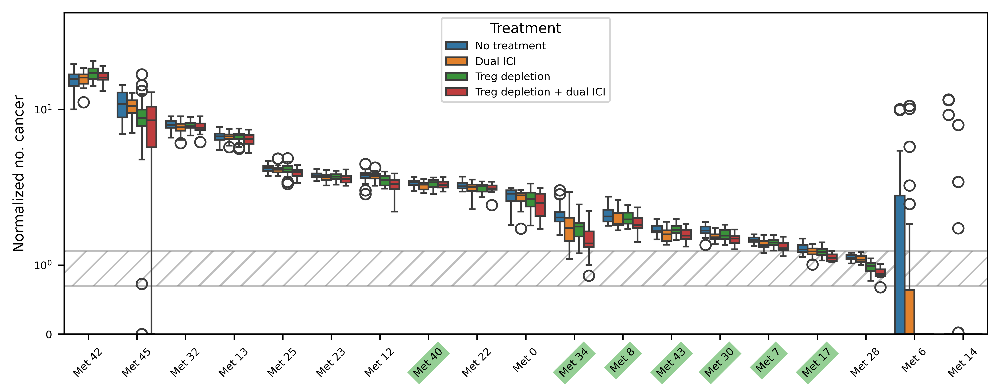

In [50]:
# Collect data
all_results = []
for met in mets:
    for j in range(num_replicates):
        orig = os.path.join(path_to_simulations, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        orig_tx = os.path.join(path_to_simulations, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        path = os.path.join(path_to_treg_dep, f"mIHC_{met + 100}", f"set_{j}/populations_TS.csv")
        tx_path = os.path.join(path_to_treg_dep, f"mIHC_{met + 100}_tx", f"set_{j}/populations_TS.csv")
        orig_data = pd.read_csv(orig, header=0)
        orig_tx_data = pd.read_csv(orig_tx, header=0)
        data = pd.read_csv(path, header=0)
        tx_data = pd.read_csv(tx_path, header=0)
        all_results.append([orig_data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "No treatment"])
        all_results.append([orig_tx_data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "Dual ICI"])
        all_results.append([data["c"].tolist()[-1], data["c"].tolist()[0], f"Met {met}", "Treg depletion"])
        all_results.append([tx_data["c"].tolist()[-1], tx_data["c"].tolist()[0], f"Met {met}", "Treg depletion + dual ICI"])

all_results = pd.DataFrame(all_results, columns=["Final cancer", "Initial cancer", "Met", "Treatment"])
all_results["Normalized no. cancer"] = all_results["Final cancer"].astype(float) / all_results["Initial cancer"].astype(float)
all_results["Normalized sqrt(no. cancer)"] = np.sqrt(all_results["Final cancer"].astype(float)) / np.sqrt(all_results["Initial cancer"].astype(float))

# Set tab10 colormap as the default
colors = plt.get_cmap('tab10').colors
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)

# Set order of metastases based on endpoint size
all_results['Met'] = all_results['Met'].astype('category')
all_results['Met'] = all_results['Met'].cat.reorder_categories(
    ['Met 42', 'Met 45', 'Met 32', 'Met 13', 'Met 25', 'Met 23', 'Met 12', 'Met 40', 'Met 22', 'Met 0', 'Met 34', 
     'Met 8', 'Met 43', 'Met 30', 'Met 7', 'Met 17', 'Met 28', 'Met 6', 'Met 14'])

# Plot the data
fig, ax = plt.subplots(1, 1, figsize=(8, 3.2), dpi=600)
ax.fill_between(np.arange(-1, 20), 0.7, 1.2, color='grey', alpha=0.5, hatch="//", facecolor='none')
sns.boxplot(data=all_results, x="Met", y="Normalized no. cancer", hue="Treatment", ax=ax)
ax.set(yscale='symlog', ylim=(0, 60), title="", xlabel="", ylabel="Normalized no. cancer")
ax.tick_params(axis='x', rotation=45)

classes = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0]
classes_to_color = {0:'none', 1:'tab:green'}
labels = ax.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

fig.tight_layout()

In [51]:
table = pd.pivot_table(all_results, values=["Normalized no. cancer"], index=["Met", "Treatment"], aggfunc="mean")
table = table.reset_index(level=1)
wide = table.pivot(columns="Treatment", values="Normalized no. cancer")
wide = wide[["No treatment", "Dual ICI", "Treg depletion", "Treg depletion + dual ICI"]]
wide["ICI prop"] = -100*((wide["No treatment"] - wide["Dual ICI"]) / wide["No treatment"])
wide["Treg block prop"] = -100*((wide["No treatment"] - wide["Treg depletion"]) / wide["No treatment"])
wide["Treg block + ICI prop"] = -100*((wide["No treatment"] - wide["Treg depletion + dual ICI"]) / wide["No treatment"])

wide

/tmp/SLURM_6780182/ipykernel_3468985/186242909.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  table = pd.pivot_table(all_results, values=["Normalized no. cancer"], index=["Met", "Treatment"], aggfunc="mean")


Treatment,No treatment,Dual ICI,Treg depletion,Treg depletion + dual ICI,ICI prop,Treg block prop,Treg block + ICI prop
Met,,,,,,,
Met 42,17.407742,17.692903,19.541935,18.383226,1.638129,12.260025,5.603736
Met 45,10.962034,10.501695,8.338305,7.525424,-4.199394,-23.934690,-31.350114
Met 32,7.497944,7.154019,7.398879,7.220561,-4.586927,-1.321234,-3.699457
Met 13,6.034516,6.031613,6.052581,5.800323,-0.048110,0.299353,-3.880900
Met 25,3.339033,3.294572,3.285651,3.100669,-1.331552,-1.598753,-7.138722
Met 23,2.949346,2.848411,2.866075,2.783925,-3.422270,-2.823373,-5.608720
Met 12,2.913043,2.882846,2.695336,2.503557,-1.036635,-7.473541,-14.056988
Met 40,2.551756,2.435691,2.532178,2.465948,-4.548458,-0.767254,-3.362702
Met 22,2.451111,2.343232,2.359091,2.330707,-4.401220,-3.754224,-4.912223


In [52]:
from scipy.stats import normaltest

stat_results = []
for met in wide.index:
    notx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "No treatment")]["Normalized no. cancer"]
    tx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "Dual ICI")]["Normalized no. cancer"]
    dep_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "Treg depletion")]["Normalized no. cancer"]
    dep_tx_vals = all_results[(all_results["Met"] == met) & (all_results["Treatment"] == "Treg depletion + dual ICI")]["Normalized no. cancer"]

    if (met == "Met 14") or (met == "Met 6"): # or (met == "Met 45"):
        result = [mannwhitneyu(notx_vals, dep_vals),
                  mannwhitneyu(notx_vals, dep_tx_vals),
                  mannwhitneyu(tx_vals, dep_vals),
                  mannwhitneyu(tx_vals, dep_tx_vals)]
    else:
        results = [ttest_ind(notx_vals, dep_vals),
                   ttest_ind(notx_vals, dep_tx_vals),
                   ttest_ind(tx_vals, dep_vals),
                   ttest_ind(tx_vals, dep_tx_vals)]
    p_vals = np.array(results)[:,1]
    stat_results.append(p_vals)
stat_results = np.array(stat_results)

# This slicing retreives the p-value
wide["notx vs. dep"] = stat_results[:,0]
wide["notx vs. dep + ICI"] = stat_results[:,1]
wide["ICI vs. dep"] = stat_results[:,2]
wide["ICI vs. dep + ICI"] = stat_results[:,3]

# We calculate the effect sizes for each comparison
wide["notx vs. dep eff"] = -100*((wide["No treatment"] - wide["Treg depletion"]) / wide["No treatment"])
wide["notx vs. dep + ICI eff"] = -100*((wide["No treatment"] - wide["Treg depletion + dual ICI"]) / wide["No treatment"])
wide["ICI vs. dep eff"] = -100*((wide["Dual ICI"] - wide["Treg depletion"]) / wide["Dual ICI"])
wide["ICI vs. dep + ICI eff"] = -100*((wide["Dual ICI"] - wide["Treg depletion + dual ICI"]) / wide["Dual ICI"])
effects = wide[["notx vs. dep eff", "notx vs. dep + ICI eff", "ICI vs. dep eff", "ICI vs. dep + ICI eff"]]

# Filter effects for significant p-values -- if the effect is zero it's because the p-value is >= 0.05
pvals = wide[["notx vs. dep", "notx vs. dep + ICI", "ICI vs. dep", "ICI vs. dep + ICI"]]
treg_pval_table = effects * (pvals < 0.05).to_numpy()

treg_pval_table

Treatment,notx vs. dep eff,notx vs. dep + ICI eff,ICI vs. dep eff,ICI vs. dep + ICI eff
Met,,,,
Met 42,12.260025,0.000000,10.450700,0.000000
Met 45,-23.934690,-31.350114,-20.600387,-28.340865
Met 32,-0.000000,-0.000000,0.000000,0.000000
Met 13,0.000000,-0.000000,0.000000,-0.000000
Met 25,-0.000000,-7.138722,-0.000000,-5.885539
Met 23,-0.000000,-5.608720,0.000000,-0.000000
Met 12,-7.473541,-14.056988,-6.504333,-13.156740
Met 40,-0.000000,-0.000000,0.000000,0.000000
Met 22,-0.000000,-4.912223,0.000000,-0.000000


In [53]:
conds = ["No treatment", "Dual ICI", "Treg depletion", "Treg depletion + dual ICI"]
for cond in conds:
    num_elim = sum(all_results[(all_results["Met"] == "Met 6") & (all_results["Treatment"] == cond)]["Normalized no. cancer"] == 0)
    print(f"For {cond}, {100*num_elim/25:.2f}% ({num_elim}) replicates are CR in MET 6.")
print('\n')
for cond in conds:
    num_elim = sum(all_results[(all_results["Met"] == "Met 14") & (all_results["Treatment"] == cond)]["Normalized no. cancer"] == 0)
    print(f"For {cond}, {100*num_elim/25:.2f}% ({num_elim}) replicates are CR in MET 14.")
print('\n')
for cond in conds:
    num_elim = sum(all_results[(all_results["Met"] == "Met 45") & (all_results["Treatment"] == cond)]["Normalized no. cancer"] == 0)
    print(f"For {cond}, {100*num_elim/25:.2f}% ({num_elim}) replicates are CR in MET 45.")

For No treatment, 60.00% (15) replicates are CR in MET 6.
For Dual ICI, 56.00% (14) replicates are CR in MET 6.
For Treg depletion, 100.00% (25) replicates are CR in MET 6.
For Treg depletion + dual ICI, 100.00% (25) replicates are CR in MET 6.


For No treatment, 88.00% (22) replicates are CR in MET 14.
For Dual ICI, 80.00% (20) replicates are CR in MET 14.
For Treg depletion, 100.00% (25) replicates are CR in MET 14.
For Treg depletion + dual ICI, 100.00% (25) replicates are CR in MET 14.


For No treatment, 0.00% (0) replicates are CR in MET 45.
For Dual ICI, 0.00% (0) replicates are CR in MET 45.
For Treg depletion, 8.00% (2) replicates are CR in MET 45.
For Treg depletion + dual ICI, 16.00% (4) replicates are CR in MET 45.


The below cell generates **Figure 7B** and **D**, which show which mets undergo statistically significant changes in cancer growth when either MDSC or Treg blockade is paired with dual ICI.

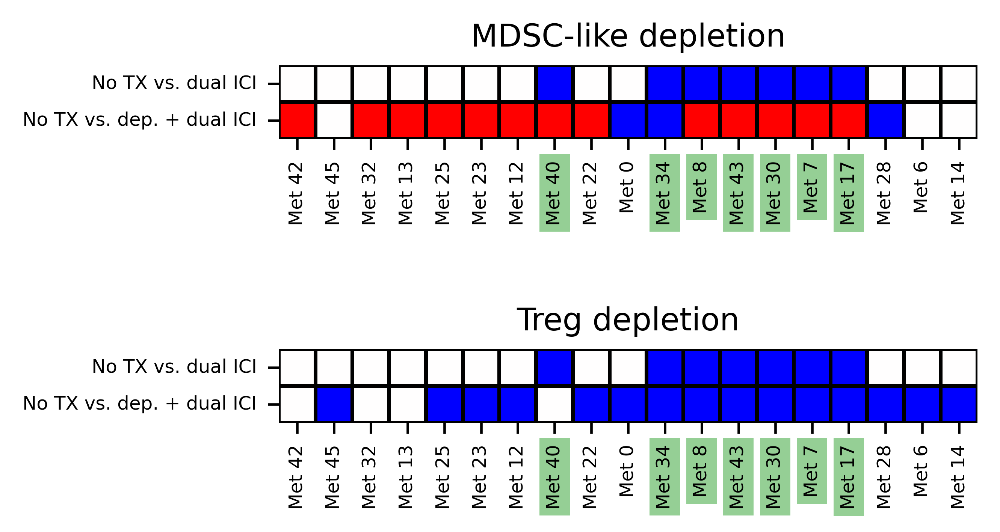

In [54]:
mets = treg_pval_table.index.to_list()
comps = ["No TX vs. dual ICI", "No TX vs. dep. + dual ICI"]
ici_fx = [0, 0, 0, 0, 0, 0, 0, -1., 0, 0, -1., -1., -1., -1., -1., -1., 0, 0, 0]

# Only get Dep + dual ICI vs. no TX
right_block = np.array([ici_fx, treg_pval_table.map(lambda x: (-1 if x < 0 else (1 if x > 0 else 0))).values[:,1]])
left_block = np.array([ici_fx, mdsc_pval_table.map(lambda x: (-1 if x < 0 else (1 if x > 0 else 0))).values[:,1]])

fig = plt.figure(figsize=(4, 3), dpi=600)
grid = gridspec.GridSpec(2, 1)
ax0 = fig.add_subplot(grid[0])
ax1 = fig.add_subplot(grid[1])

sns.heatmap(left_block, ax=ax0, cbar=False, xticklabels=mets, yticklabels=comps, cmap="bwr", linewidths=1, linecolor="black", center=0)
sns.heatmap(right_block, ax=ax1, cbar=False, xticklabels=mets, yticklabels=comps, cmap="bwr", linewidths=1, linecolor="black", center=0)
ax0.set_aspect(1)
ax1.set_aspect(1)

ax0.set(title="MDSC-like depletion")
ax1.set(title="Treg depletion")

classes = [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0]
classes_to_color = {0:'none', 1:'tab:green'}

labels = ax0.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))

labels = ax1.get_xticklabels()
for i, label in enumerate(labels):
    label.set_bbox(dict(facecolor=classes_to_color[classes[i]], alpha=0.5, edgecolor='none', pad=2))